<img src="https://thumb.wikimedia.org/wikipedia/en/thumb/0/0f/Ola_Cabs_logo.svg/3840px-Ola_Cabs_logo.svg.png?utm_source=en.wikipedia.org&amp;utm_campaign=index&amp;utm_content=thumbnail" jsaction="" class="sFlh5c FyHeAf uT7N3d" style="max-width: 1000px; --xGflle: 2.8465530022238696;" alt="File:Ola Cabs logo.svg - Wikipedia" jsname="kn3ccd">

# 🚖 Ola Ride Insights — End-to-End Data Analytics Project
**Domain:** Ride-Sharing & Mobility Analytics &nbsp;|&nbsp; **Period:** July 2024 &nbsp;|&nbsp; **Scale:** 103K bookings, 7 vehicle types, 50 Bengaluru localities

**Author:** P Suman Sangeet · Data Science & AI Intern, INNOVEXIS · LABMENTIX Bold Analytics Cohort 2025

---
### Business problem
Ola generates large volumes of booking, fare, cancellation and rating data. This notebook turns the raw July-2024 data into decisions on **demand, revenue leakage, cancellations and service quality**.

### Pipeline
| Step | What | Output |
|---|---|---|
| 1 | Setup & theme | Consistent brand styling |
| 2 | Data understanding | Structure, dictionary, structural-missingness audit |
| 3 | Cleaning & feature engineering | Analysis-ready dataset + validation checks |
| 4 | KPI scorecard | Headline metrics |
| 5 | Overall view | Volume trend, status mix, demand heatmap |
| 6 | Vehicle-type view | Distance, revenue, success rate by vehicle |
| 7 | Revenue view | Payment mix, leakage waterfall, top customers, distance distribution |
| 8 | Cancellation view | Customer vs driver reasons, hot spots |
| 9 | Ratings view | Driver vs customer rating behaviour |
| 10 | Deeper EDA | Outliers, correlations, geography |
| 11 | SQL analysis | 10 business queries, cross-validated against pandas |
| 12 | Insights & recommendations | Data-driven, auto-computed |
| 13 | Export | Clean CSV + SQLite + summary tables for Power BI / Streamlit |

> Charts are **interactive (Plotly)** — hover for values, click legend items to isolate, drag to zoom, use dropdowns/range sliders where provided.

## Step 1 · Setup & Visual Theme

In [1]:
import warnings, sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ---- Brand palette -------------------------------------------------------
INK, LIME = "#1B1F23", "#C6D82B"
STATUS_ORDER  = ["Success", "Canceled by Driver", "Canceled by Customer", "Driver Not Found"]
STATUS_COLORS = {"Success": "#2E9E6B", "Canceled by Driver": "#E4572E",
                 "Canceled by Customer": "#F2A541", "Driver Not Found": "#8A94A0"}
VEHICLES = ["Prime Sedan", "Prime SUV", "Prime Plus", "Mini", "Auto", "Bike", "E-Bike"]
VEH_COLORS = dict(zip(VEHICLES, ["#1B1F23", "#3A6EA5", "#6C5CE7", "#2E9E6B", "#F2A541", "#E4572E", "#00A8A8"]))
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

pio.templates["ola"] = go.layout.Template(layout=dict(
    font=dict(family="Inter, Segoe UI, Arial, sans-serif", size=13, color=INK),
    title=dict(x=0.02, xanchor="left", font=dict(size=20)),
    paper_bgcolor="white", plot_bgcolor="white",
    xaxis=dict(showgrid=False, linecolor="#CFD4DA", zeroline=False),
    yaxis=dict(gridcolor="#EEF0F3", zeroline=False),
    legend=dict(orientation="h", y=-0.2, x=0),
    margin=dict(l=60, r=30, t=90, b=60),
    hoverlabel=dict(bgcolor="white", font_size=13)))
pio.templates.default = "plotly_white+ola"

def show(fig, title, subtitle=None, height=480):
    """Apply a consistent title block and render."""
    t = f"<b>{title}</b>" + (f"<br><span style='font-size:13px;color:#6B7580'>{subtitle}</span>" if subtitle else "")
    fig.update_layout(title_text=t, height=height)
    fig.show()

def box_traces(d, by, y, color_fn, order=None):
    """Pre-aggregated box stats (keeps the notebook light: no raw points are embedded)."""
    g = d.groupby(by, observed=True)[y]
    out = []
    for k in (order or sorted(d[by].unique())):
        v = g.get_group(k); q1, med, q3 = v.quantile([.25, .5, .75]); iqr = q3 - q1
        lo, hi = v[v >= q1 - 1.5 * iqr].min(), v[v <= q3 + 1.5 * iqr].max()
        out.append(go.Box(x=[k], name=str(k)[:10], q1=[q1], median=[med], q3=[q3], lowerfence=[lo], upperfence=[hi], mean=[v.mean()],
                          marker_color=color_fn(k), showlegend=False))
    return out

def insight(text):
    display(Markdown(f"> 💡 **Insight:** {text}"))

print("Environment ready ✔")

Environment ready ✔


## Step 2 · Data Understanding
Following the EDA checklist: shape → dtypes → missing values → duplicates → distributions → categorical cardinality.

In [2]:
# Place OLA_DataSet.xlsx next to this notebook (or edit the path list)
CANDIDATES = [Path("OLA_DataSet.xlsx"), Path("data/OLA_DataSet.xlsx"), Path("/content/OLA_DataSet.xlsx")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_PATH, "OLA_DataSet.xlsx not found - place it beside the notebook."

raw = pd.read_excel(DATA_PATH, sheet_name="July", na_values=["null", "NULL"])
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]} | Memory: {raw.memory_usage(deep=True).sum()/1e6:.1f} MB")
display(raw.head())

Rows: 103,024 | Columns: 20 | Memory: 78.5 MB


,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.00,30.00,NaN,NaN,No,NaN,158,Cash,13,4.10,4.00,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.00,130.00,NaN,NaN,No,NaN,386,UPI,40,4.20,4.80,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.00,80.00,NaN,NaN,No,NaN,822,Credit Card,45,4.00,3.00,https://cdn-icons-png.flaticon.com/128/3202/32...


In [3]:
# Data dictionary: type, completeness, cardinality, sample
dictionary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
    "example": raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None).astype(str).str[:30],
})
display(dictionary)
print("Duplicate rows       :", raw.duplicated().sum())
print("Duplicate Booking_IDs:", raw["Booking_ID"].duplicated().sum())

,dtype,non_null,missing_%,unique,example
Date,datetime64[us],103024,0.00,40214,2024-07-26 14:00:00
Time,object,103024,0.00,1440,14:00:00
Booking_ID,str,103024,0.00,103024,CNR7153255142
Booking_Status,str,103024,0.00,4,Canceled by Driver
Customer_ID,str,103024,0.00,94544,CID713523
Vehicle_Type,str,103024,0.00,7,Prime Sedan
Pickup_Location,str,103024,0.00,50,Tumkur Road
Drop_Location,str,103024,0.00,50,RT Nagar
V_TAT,float64,63967,37.90,40,203.0
C_TAT,float64,63967,37.90,25,30.0


Duplicate rows       : 0
Duplicate Booking_IDs: 0


In [4]:
# Are the missing values errors? -> No. They are STRUCTURAL: a field only exists when the business event happens.
miss = (raw.drop(columns="Vehicle Images").isna().groupby(raw["Booking_Status"]).mean() * 100).T
display(miss.style.background_gradient(cmap="Reds", axis=None).format("{:.0f}%")
        .set_caption("% missing by Booking_Status (100% = field never applies to that status)"))
insight("Ratings, payment method, TAT and incomplete-ride flags exist **only for Success** bookings; cancel reasons exist only for the matching cancel type. "
        "These nulls are *by design*, so they are **not imputed** (imputation would fabricate ratings and payments for rides that never happened).")

Booking_Status,Canceled by Customer,Canceled by Driver,Driver Not Found,Success
Date,0%,0%,0%,0%
Time,0%,0%,0%,0%
Booking_ID,0%,0%,0%,0%
Booking_Status,0%,0%,0%,0%
Customer_ID,0%,0%,0%,0%
Vehicle_Type,0%,0%,0%,0%
Pickup_Location,0%,0%,0%,0%
Drop_Location,0%,0%,0%,0%
V_TAT,100%,100%,100%,0%
C_TAT,100%,100%,100%,0%


> 💡 **Insight:** Ratings, payment method, TAT and incomplete-ride flags exist **only for Success** bookings; cancel reasons exist only for the matching cancel type. These nulls are *by design*, so they are **not imputed** (imputation would fabricate ratings and payments for rides that never happened).

## Step 3 · Cleaning & Feature Engineering
Standardise labels, build time features, unify cancellation reasons, and **validate** business rules with assertions.

In [5]:
df = raw.drop(columns=["Vehicle Images"]).copy()

# 1) Standardise categories (dashboard spec uses "E-Bike")
df["Vehicle_Type"] = df["Vehicle_Type"].replace({"eBike": "E-Bike"})
for c in df.select_dtypes("object").columns.difference(["Date", "Time"]):
    df[c] = df[c].astype("string").str.strip()

# 2) Time features
df["Booking_DT"]   = pd.to_datetime(df["Date"])
df["Booking_Date"] = df["Booking_DT"].dt.normalize()
df["Hour"]         = df["Booking_DT"].dt.hour
df["Weekday"]      = pd.Categorical(df["Booking_DT"].dt.day_name(), categories=WEEKDAYS, ordered=True)
df["Is_Weekend"]   = df["Booking_DT"].dt.dayofweek >= 5
df["Day_Part"]     = pd.cut(df["Hour"], bins=[-1, 5, 11, 16, 21, 23],
                            labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-16)", "Evening (17-21)", "Late Night (22-23)"]).astype(str)

# 3) Business flags & unified cancellation fields
df["Is_Success"] = df["Booking_Status"].eq("Success")
df["Is_Incomplete"] = df["Incomplete_Rides"].eq("Yes")
df["Cancel_Reason"] = df["Canceled_Rides_by_Customer"].fillna(df["Canceled_Rides_by_Driver"])
df["Cancel_By"] = np.select([df["Booking_Status"].eq("Canceled by Customer"), df["Booking_Status"].eq("Canceled by Driver")],
                            ["Customer", "Driver"], default=None)
df["Same_Pickup_Drop"] = df["Pickup_Location"].eq(df["Drop_Location"])

df = df.drop(columns=["Date", "Time"])
succ = df[df["Is_Success"]].copy()
print(f"Clean dataset: {df.shape[0]:,} rows x {df.shape[1]} cols | Successful rides: {len(succ):,}")

Clean dataset: 103,024 rows x 28 cols | Successful rides: 63,967


In [6]:
# ---- Validation: business-rule assertions --------------------------------
checks = {
    "Booking_ID is unique"                       : df["Booking_ID"].is_unique,
    "Only 4 known booking statuses"              : set(df["Booking_Status"]) == set(STATUS_ORDER),
    "Exactly 7 vehicle types"                    : set(df["Vehicle_Type"]) == set(VEHICLES),
    "Booking_Value > 0 for all rows"             : (df["Booking_Value"] > 0).all(),
    "Distance == 0 for non-success"              : (df.loc[~df["Is_Success"], "Ride_Distance"] == 0).all(),
    "Distance > 0 for success"                   : (succ["Ride_Distance"] > 0).all(),
    "Ratings only on success, within 1-5"        : df.loc[~df["Is_Success"], ["Driver_Ratings", "Customer_Rating"]].isna().all().all()
                                                   and succ[["Driver_Ratings", "Customer_Rating"]].stack().between(1, 5).all(),
    "Payment method only on success"             : df.loc[~df["Is_Success"], "Payment_Method"].isna().all(),
    "Data covers a single month (Jul-2024)"      : df["Booking_DT"].dt.to_period("M").nunique() == 1,
}
display(pd.Series(checks, name="Passed").map({True: "✅ PASS", False: "❌ FAIL"}).to_frame())
assert all(checks.values()), "Validation failed - inspect above"
display(df.head(3).T)

,Passed
Booking_ID is unique,✅ PASS
Only 4 known booking statuses,✅ PASS
Exactly 7 vehicle types,✅ PASS
Booking_Value > 0 for all rows,✅ PASS
Distance == 0 for non-success,✅ PASS
Distance > 0 for success,✅ PASS
"Ratings only on success, within 1-5",✅ PASS
Payment method only on success,✅ PASS
Data covers a single month (Jul-2024),✅ PASS


,0,1,2
Booking_ID,CNR7153255142,CNR2940424040,CNR2982357879
Booking_Status,Canceled by Driver,Success,Success
Customer_ID,CID713523,CID225428,CID270156
Vehicle_Type,Prime Sedan,Bike,Prime SUV
Pickup_Location,Tumkur Road,Magadi Road,Sahakar Nagar
Drop_Location,RT Nagar,Varthur,Varthur
V_TAT,NaN,203.00,238.00
C_TAT,NaN,30.00,130.00
Canceled_Rides_by_Customer,<NA>,<NA>,<NA>
Canceled_Rides_by_Driver,Personal & Car related issue,<NA>,<NA>


## Step 4 · KPI Scorecard

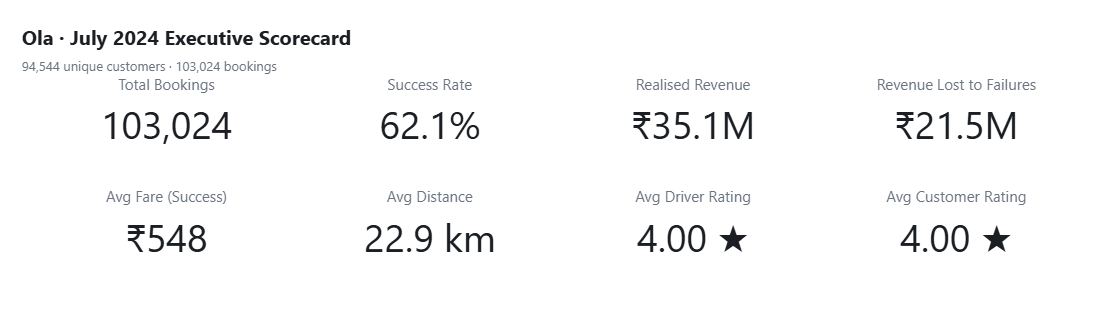

> 💡 **Insight:** Only **62.1%** of bookings convert to completed rides; **37.9%** fail, leaving **₹21.5M** of booking value unrealised (**38%** of total demand value).

In [7]:
K = dict(
    bookings = len(df), success = len(succ),
    success_rate = len(succ) / len(df) * 100,
    driver_cancel = df["Booking_Status"].eq("Canceled by Driver").mean() * 100,
    cust_cancel   = df["Booking_Status"].eq("Canceled by Customer").mean() * 100,
    no_driver     = df["Booking_Status"].eq("Driver Not Found").mean() * 100,
    revenue = succ["Booking_Value"].sum(), lost = df.loc[~df["Is_Success"], "Booking_Value"].sum(),
    avg_fare = succ["Booking_Value"].mean(), avg_dist = succ["Ride_Distance"].mean(),
    total_dist = succ["Ride_Distance"].sum(), avg_drv = succ["Driver_Ratings"].mean(), avg_cust = succ["Customer_Rating"].mean(),
    customers = df["Customer_ID"].nunique(),
)
tiles = [
    ("Total Bookings", K["bookings"], "", "", ",.0f"), ("Success Rate", K["success_rate"], "", "%", ".1f"),
    ("Realised Revenue", K["revenue"]/1e6, "₹", "M", ".1f"), ("Revenue Lost to Failures", K["lost"]/1e6, "₹", "M", ".1f"),
    ("Avg Fare (Success)", K["avg_fare"], "₹", "", ",.0f"), ("Avg Distance", K["avg_dist"], "", " km", ".1f"),
    ("Avg Driver Rating", K["avg_drv"], "", " ★", ".2f"), ("Avg Customer Rating", K["avg_cust"], "", " ★", ".2f"),
]
fig = make_subplots(rows=2, cols=4, specs=[[{"type": "indicator"}] * 4] * 2, vertical_spacing=0.25)
for i, (t, v, pre, suf, fmt) in enumerate(tiles):
    fig.add_trace(go.Indicator(mode="number", value=v, title={"text": t, "font": {"size": 15, "color": "#6B7580"}},
                               number={"prefix": pre, "suffix": suf, "valueformat": fmt, "font": {"size": 38, "color": INK}}),
                  row=i // 4 + 1, col=i % 4 + 1)
show(fig, "Ola · July 2024 Executive Scorecard", f"{K['customers']:,} unique customers · {K['bookings']:,} bookings", height=330)
fails = 100 - K["success_rate"]
insight(f"Only **{K['success_rate']:.1f}%** of bookings convert to completed rides; **{fails:.1f}%** fail, leaving **₹{K['lost']/1e6:.1f}M** of booking value unrealised "
        f"(**{K['lost']/(K['lost']+K['revenue'])*100:.0f}%** of total demand value).")

## Step 5 · Overall View — Volume & Booking Status
**Q1 Ride volume over time · Q2 Booking-status breakdown** (+ demand patterns by hour/weekday)

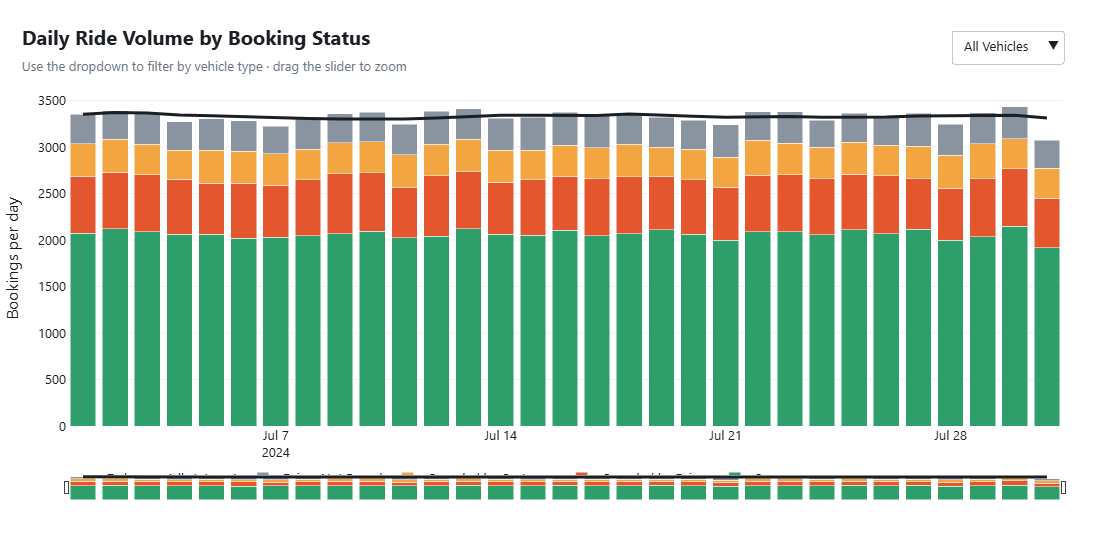

> 💡 **Insight:** Demand is very stable: **3,323 bookings/day** on average (min 3,072, max 3,432; coefficient of variation 2.1%). No growth/decline trend in the month - volume is supply- and conversion-driven, not demand-spiky.

In [8]:
# Interactive daily volume: filter by vehicle type with the dropdown, zoom with the range slider
def daily_counts(d):
    return d.groupby(["Booking_Date", "Booking_Status"]).size().unstack(fill_value=0).reindex(columns=STATUS_ORDER, fill_value=0)

options = ["All Vehicles"] + VEHICLES
fig = go.Figure()
for i, opt in enumerate(options):
    d = df if opt == "All Vehicles" else df[df["Vehicle_Type"] == opt]
    t = daily_counts(d)
    for s in STATUS_ORDER:
        fig.add_trace(go.Bar(x=t.index, y=t[s], name=s, marker_color=STATUS_COLORS[s], visible=(i == 0),
                             hovertemplate="%{x|%d %b}<br>" + s + ": %{y:,}<extra></extra>"))
    fig.add_trace(go.Scatter(x=t.index, y=t.sum(axis=1).rolling(7, min_periods=1).mean(), name="7-day avg (all statuses)",
                             line=dict(color=INK, width=3), visible=(i == 0)))
n = len(STATUS_ORDER) + 1
fig.update_layout(barmode="stack",
    updatemenus=[dict(type="dropdown", x=1.0, xanchor="right", y=1.18, buttons=[
        dict(label=o, method="update", args=[{"visible": [j // n == k for j in range(len(options) * n)]}]) for k, o in enumerate(options)])],
    xaxis=dict(rangeslider=dict(visible=True, thickness=0.06)), yaxis_title="Bookings per day")
show(fig, "Daily Ride Volume by Booking Status", "Use the dropdown to filter by vehicle type · drag the slider to zoom", height=560)
daily_total = df.groupby("Booking_Date").size()
insight(f"Demand is very stable: **{daily_total.mean():,.0f} bookings/day** on average (min {daily_total.min():,}, max {daily_total.max():,}; "
        f"coefficient of variation {daily_total.std()/daily_total.mean()*100:.1f}%). No growth/decline trend in the month - volume is supply- and conversion-driven, not demand-spiky.")

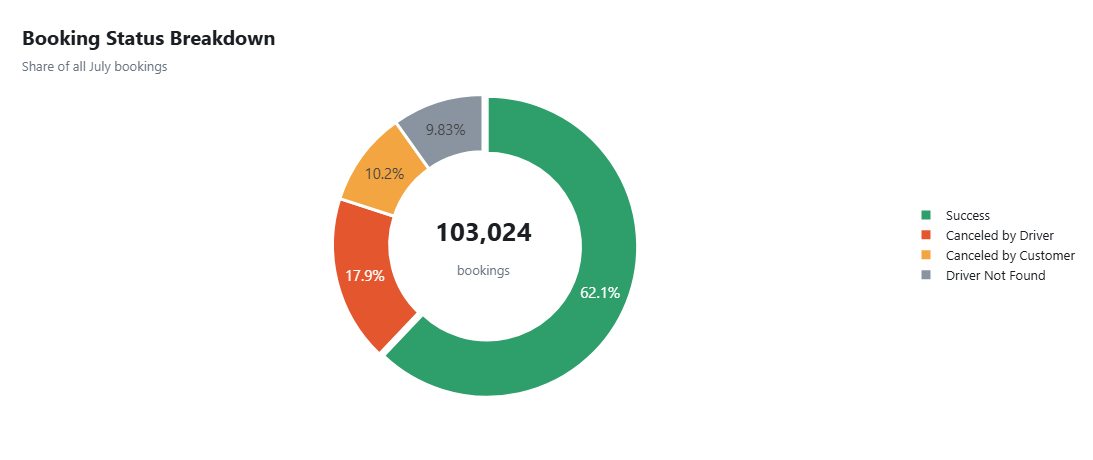

> 💡 **Insight:** **Driver-side failures dominate**: drivers cancel **17.9%** of bookings - ~1.8x the customer cancel rate (10.2%). A further **9.8%** end with no driver found.

In [9]:
st = df["Booking_Status"].value_counts().reindex(STATUS_ORDER)
fig = go.Figure(go.Pie(labels=st.index, values=st.values, hole=0.62, sort=False, direction="clockwise",
                       marker=dict(colors=[STATUS_COLORS[s] for s in st.index], line=dict(color="white", width=3)),
                       textinfo="percent", textfont_size=15, pull=[0.03, 0, 0, 0],
                       hovertemplate="%{label}<br>%{value:,} bookings (%{percent})<extra></extra>"))
fig.add_annotation(text=f"<b>{len(df):,}</b><br><span style='font-size:13px;color:#6B7580'>bookings</span>", showarrow=False, font_size=26)
fig.update_layout(legend=dict(orientation="v", y=0.5, x=1.0))
show(fig, "Booking Status Breakdown", "Share of all July bookings", height=460)
insight(f"**Driver-side failures dominate**: drivers cancel **{K['driver_cancel']:.1f}%** of bookings - ~{K['driver_cancel']/K['cust_cancel']:.1f}x the customer cancel rate ({K['cust_cancel']:.1f}%). "
        f"A further **{K['no_driver']:.1f}%** end with no driver found.")

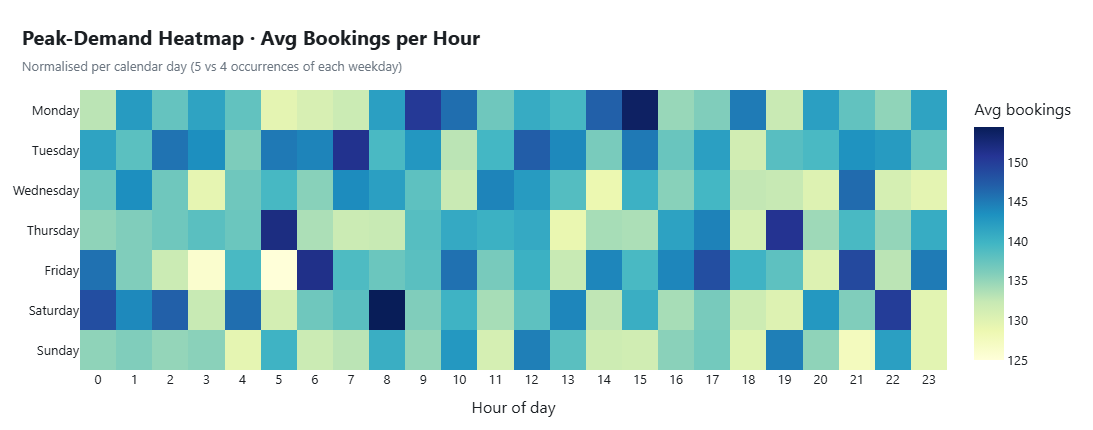

> 💡 **Insight:** Demand is **flat across the day** (135-142 bookings/hour, peak at 12:00) and across weekdays (busiest Tuesday at 3,385/day vs Sunday 3,253/day). No classic commute peaks - driver allocation should be **uniform and 24x7**, not rush-hour-weighted.

In [10]:
# Demand pattern: hour x weekday heatmap. Weekday counts are normalised per calendar day,
# because July-2024 has 5 Mon/Tue/Wed but only 4 of the other days (raw totals would mislead).
days_per_weekday = df.groupby("Weekday", observed=True)["Booking_Date"].nunique()
hm = df.pivot_table(index="Weekday", columns="Hour", values="Booking_ID", aggfunc="count", observed=True)
hm = hm.div(days_per_weekday, axis=0).reindex(WEEKDAYS)
fig = px.imshow(hm, aspect="auto", color_continuous_scale="YlGnBu", labels=dict(x="Hour of day", y="", color="Avg bookings"))
fig.update_traces(hovertemplate="%{y}, %{x}:00<br>Avg bookings: %{z:.0f}<extra></extra>")
fig.update_xaxes(dtick=1)
show(fig, "Peak-Demand Heatmap · Avg Bookings per Hour", "Normalised per calendar day (5 vs 4 occurrences of each weekday)", height=430)

wk = (df.groupby("Weekday", observed=True).size() / days_per_weekday).reindex(WEEKDAYS)
hr = df.groupby("Hour").size() / df["Booking_Date"].nunique()
insight(f"Demand is **flat across the day** ({hr.min():.0f}-{hr.max():.0f} bookings/hour, peak at {hr.idxmax()}:00) and across weekdays "
        f"(busiest {wk.idxmax()} at {wk.max():,.0f}/day vs {wk.idxmin()} {wk.min():,.0f}/day). "
        "No classic commute peaks - driver allocation should be **uniform and 24x7**, not rush-hour-weighted.")

## Step 6 · Vehicle-Type View
**Q3 Top vehicle types by ride distance** + summary table (Total / Success booking value, Avg & Total distance).

In [11]:
veh = df.groupby("Vehicle_Type").agg(Bookings=("Booking_ID", "count"), Total_Booking_Value=("Booking_Value", "sum"))
vs = succ.groupby("Vehicle_Type").agg(Successful_Rides=("Booking_ID", "count"), Success_Booking_Value=("Booking_Value", "sum"),
                                      Avg_Distance_km=("Ride_Distance", "mean"), Total_Distance_km=("Ride_Distance", "sum"),
                                      Avg_Fare=("Booking_Value", "mean"), Avg_Driver_Rating=("Driver_Ratings", "mean"),
                                      Avg_Customer_Rating=("Customer_Rating", "mean"))
veh = veh.join(vs)
veh["Success_Rate_%"] = veh["Successful_Rides"] / veh["Bookings"] * 100
veh["Revenue_per_Km"] = veh["Success_Booking_Value"] / veh["Total_Distance_km"]
veh = veh.reindex(VEHICLES)
display(veh[["Bookings", "Total_Booking_Value", "Success_Booking_Value", "Avg_Distance_km", "Total_Distance_km", "Success_Rate_%", "Revenue_per_Km"]]
        .style.format({"Bookings": "{:,.0f}", "Total_Booking_Value": "₹{:,.0f}", "Success_Booking_Value": "₹{:,.0f}", "Avg_Distance_km": "{:.1f}",
                       "Total_Distance_km": "{:,.0f}", "Success_Rate_%": "{:.1f}%", "Revenue_per_Km": "₹{:.1f}"})
        .background_gradient(cmap="Greens", axis=0).set_caption("Vehicle-Type Performance Summary"))

,Bookings,Total_Booking_Value,Success_Booking_Value,Avg_Distance_km,Total_Distance_km,Success_Rate_%,Revenue_per_Km
Vehicle_Type,,,,,,,
Prime Sedan,"14,877","₹8,298,612","₹5,224,050",25.0,"234,535",63.0%,₹22.3
Prime SUV,"14,655","₹7,933,330","₹4,876,815",24.9,"223,848",61.4%,₹21.8
Prime Plus,"14,707","₹8,050,889","₹5,015,165",25.0,"227,186",61.7%,₹22.1
Mini,"14,552","₹7,990,996","₹4,885,961",25.0,"225,703",62.1%,₹21.6
Auto,"14,755","₹8,092,210","₹5,051,846",10.0,"92,043",62.1%,₹54.9
Bike,"14,662","₹7,987,054","₹4,971,968",24.9,"227,746",62.3%,₹21.8
E-Bike,"14,816","₹8,181,523","₹5,054,662",25.1,"230,842",62.0%,₹21.9


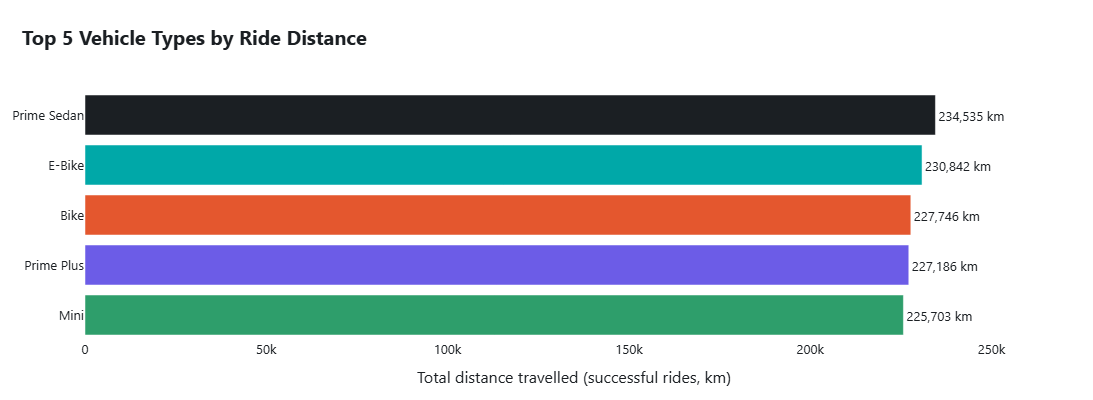

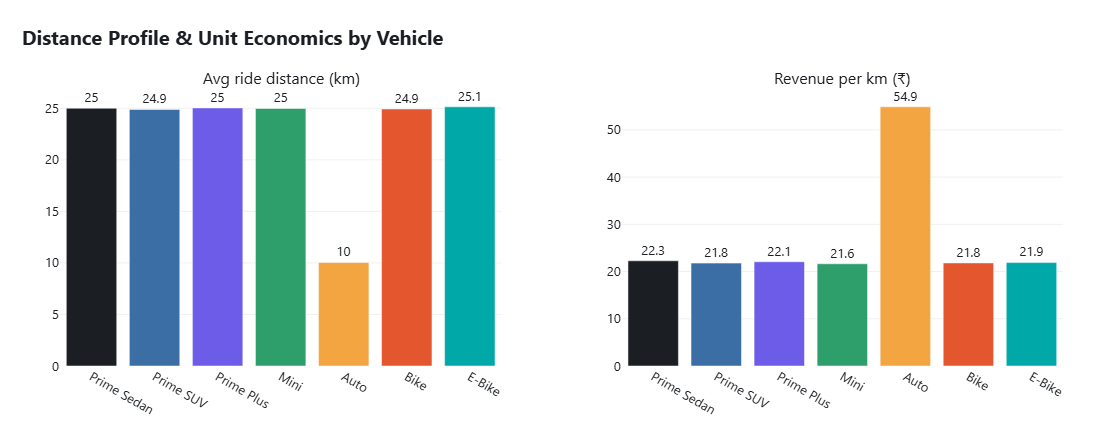

> 💡 **Insight:** **Auto is the outlier**: avg ride is only **10.0 km** vs **25.0 km** for other vehicles, yet fares are similar (avg ₹551) - so Auto earns **₹55/km vs ~₹22/km**. Prime Sedan leads on distance (234,535 km) and realised revenue.

In [12]:
top5 = veh["Total_Distance_km"].nlargest(5).sort_values()
fig = go.Figure(go.Bar(x=top5.values, y=top5.index, orientation="h", marker_color=[VEH_COLORS[v] for v in top5.index],
                       text=[f"{v:,.0f} km" for v in top5.values], textposition="outside", cliponaxis=False))
fig.update_layout(xaxis_title="Total distance travelled (successful rides, km)", xaxis_range=[0, top5.max() * 1.15])
show(fig, "Top 5 Vehicle Types by Ride Distance", height=400)

fig = make_subplots(rows=1, cols=2, subplot_titles=("Avg ride distance (km)", "Revenue per km (₹)"), horizontal_spacing=0.12)
fig.add_trace(go.Bar(x=veh.index, y=veh["Avg_Distance_km"], marker_color=[VEH_COLORS[v] for v in veh.index],
                     text=veh["Avg_Distance_km"].round(1), textposition="outside"), 1, 1)
fig.add_trace(go.Bar(x=veh.index, y=veh["Revenue_per_Km"], marker_color=[VEH_COLORS[v] for v in veh.index],
                     text=veh["Revenue_per_Km"].round(1), textposition="outside"), 1, 2)
fig.update_layout(showlegend=False)
show(fig, "Distance Profile & Unit Economics by Vehicle", height=430)
a = veh.loc["Auto"]; o = veh.drop("Auto")
insight(f"**Auto is the outlier**: avg ride is only **{a['Avg_Distance_km']:.1f} km** vs **{o['Avg_Distance_km'].mean():.1f} km** for other vehicles, "
        f"yet fares are similar (avg ₹{a['Avg_Fare']:.0f}) - so Auto earns **₹{a['Revenue_per_Km']:.0f}/km vs ~₹{o['Revenue_per_Km'].mean():.0f}/km**. "
        f"Prime Sedan leads on distance ({veh.loc['Prime Sedan','Total_Distance_km']:,.0f} km) and realised revenue.")

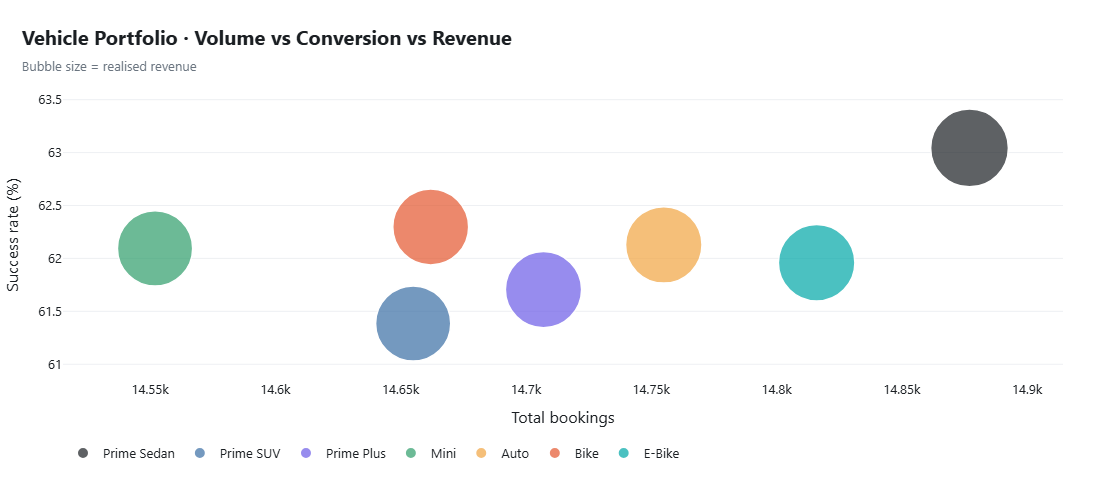

> 💡 **Insight:** Fleet performance is remarkably **homogeneous** (success rate 61.4-63.0%). Prime Sedan converts best - the issue is **platform-wide**, not a single vehicle category.

In [13]:
# Interactive bubble: bookings vs success rate, bubble = realised revenue
fig = px.scatter(veh.reset_index(), x="Bookings", y="Success_Rate_%", size="Success_Booking_Value", color="Vehicle_Type",
                 color_discrete_map=VEH_COLORS, size_max=55, hover_data={"Success_Booking_Value": ":,.0f", "Avg_Distance_km": ":.1f"})
fig.update_traces(marker=dict(line=dict(width=1.5, color="white")))
fig.update_layout(xaxis_title="Total bookings", yaxis_title="Success rate (%)", legend_title="")
show(fig, "Vehicle Portfolio · Volume vs Conversion vs Revenue", "Bubble size = realised revenue", height=480)
insight(f"Fleet performance is remarkably **homogeneous** (success rate {veh['Success_Rate_%'].min():.1f}-{veh['Success_Rate_%'].max():.1f}%). "
        f"{veh['Success_Rate_%'].idxmax()} converts best - the issue is **platform-wide**, not a single vehicle category.")

## Step 7 · Revenue View
**Q6 Revenue by payment method · Q7 Top 5 customers by booking value · Q8 Ride-distance distribution per day** (+ revenue-leakage waterfall)

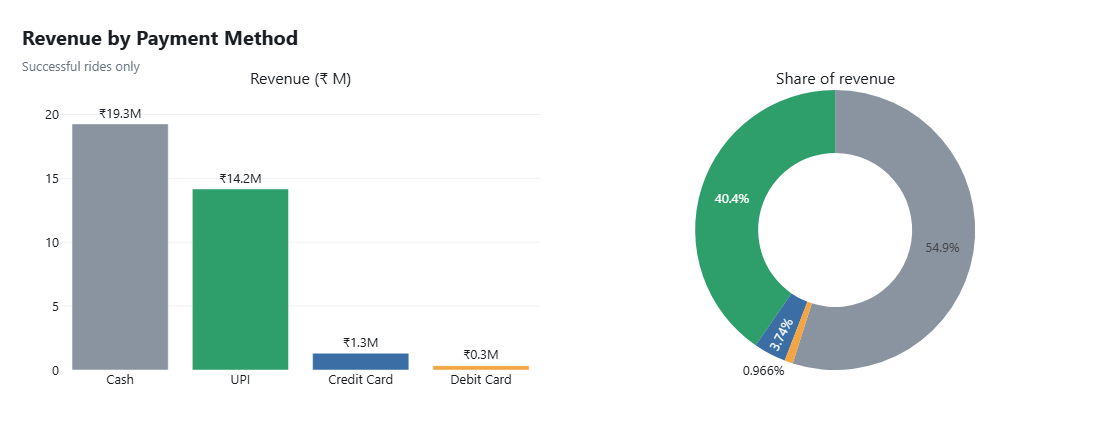

> 💡 **Insight:** **Cash still drives 55%** of revenue; UPI is a strong second (40%) and cards are marginal (5%). Digital total = 45% - UPI-first incentives are the clearest lever for cash-handling and settlement efficiency.

In [14]:
pay = succ.groupby("Payment_Method").agg(Revenue=("Booking_Value", "sum"), Rides=("Booking_ID", "count")).sort_values("Revenue", ascending=False)
pay["Share_%"] = pay["Revenue"] / pay["Revenue"].sum() * 100
PAY_COLORS = {"Cash": "#8A94A0", "UPI": "#2E9E6B", "Credit Card": "#3A6EA5", "Debit Card": "#F2A541"}
fig = make_subplots(rows=1, cols=2, specs=[[{"type": "bar"}, {"type": "pie"}]], column_widths=[0.55, 0.45], subplot_titles=("Revenue (₹ M)", "Share of revenue"))
fig.add_trace(go.Bar(x=pay.index, y=pay["Revenue"] / 1e6, marker_color=[PAY_COLORS[p] for p in pay.index],
                     text=[f"₹{v/1e6:.1f}M" for v in pay["Revenue"]], textposition="outside"), 1, 1)
fig.add_trace(go.Pie(labels=pay.index, values=pay["Revenue"], hole=0.55, marker=dict(colors=[PAY_COLORS[p] for p in pay.index]), textinfo="percent"), 1, 2)
fig.update_layout(showlegend=False)
show(fig, "Revenue by Payment Method", "Successful rides only", height=430)
digital = pay.loc[["UPI", "Credit Card", "Debit Card"], "Share_%"].sum()
insight(f"**Cash still drives {pay.loc['Cash','Share_%']:.0f}%** of revenue; UPI is a strong second ({pay.loc['UPI','Share_%']:.0f}%) and cards are marginal "
        f"({pay.loc[['Credit Card','Debit Card'],'Share_%'].sum():.0f}%). Digital total = {digital:.0f}% - UPI-first incentives are the clearest lever for cash-handling and settlement efficiency.")

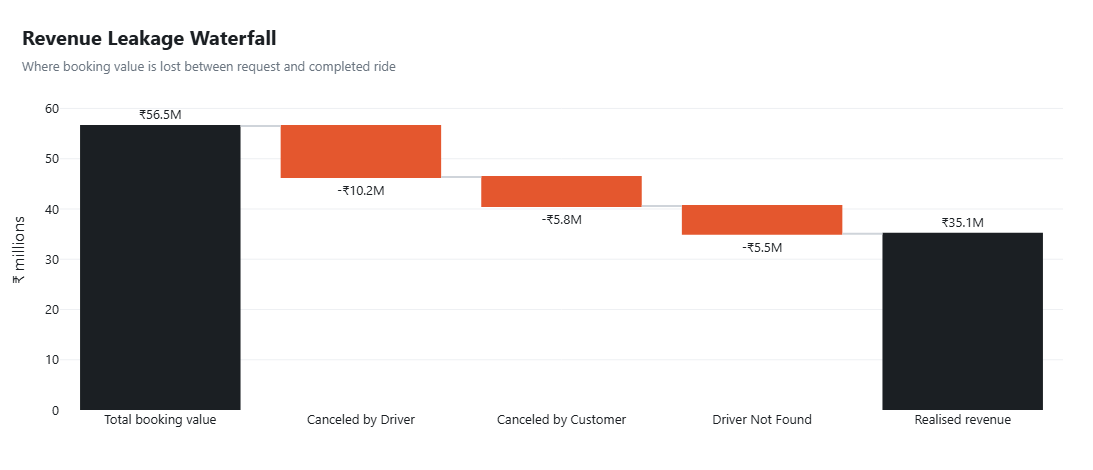

> 💡 **Insight:** Driver cancellations alone burn **₹10.2M** (18% of requested value) - the single biggest recoverable revenue pool, larger than customer cancels (₹5.8M) and unfulfilled requests (₹5.5M).

In [15]:
# Revenue leakage waterfall: from total booking value to realised revenue
by_status = df.groupby("Booking_Status")["Booking_Value"].sum().reindex(STATUS_ORDER)
fig = go.Figure(go.Waterfall(
    x=["Total booking value", "Canceled by Driver", "Canceled by Customer", "Driver Not Found", "Realised revenue"],
    measure=["absolute", "relative", "relative", "relative", "total"],
    y=[by_status.sum() / 1e6, -by_status["Canceled by Driver"] / 1e6, -by_status["Canceled by Customer"] / 1e6, -by_status["Driver Not Found"] / 1e6, 0],
    text=[f"₹{by_status.sum()/1e6:.1f}M", f"-₹{by_status['Canceled by Driver']/1e6:.1f}M", f"-₹{by_status['Canceled by Customer']/1e6:.1f}M",
          f"-₹{by_status['Driver Not Found']/1e6:.1f}M", f"₹{by_status['Success']/1e6:.1f}M"], textposition="outside",
    increasing_marker_color="#2E9E6B", decreasing_marker_color="#E4572E", totals_marker_color=INK, connector_line_color="#CFD4DA"))
fig.update_layout(yaxis_title="₹ millions", showlegend=False)
show(fig, "Revenue Leakage Waterfall", "Where booking value is lost between request and completed ride", height=470)
insight(f"Driver cancellations alone burn **₹{by_status['Canceled by Driver']/1e6:.1f}M** ({by_status['Canceled by Driver']/by_status.sum()*100:.0f}% of requested value) - "
        f"the single biggest recoverable revenue pool, larger than customer cancels (₹{by_status['Canceled by Customer']/1e6:.1f}M) and unfulfilled requests (₹{by_status['Driver Not Found']/1e6:.1f}M).")

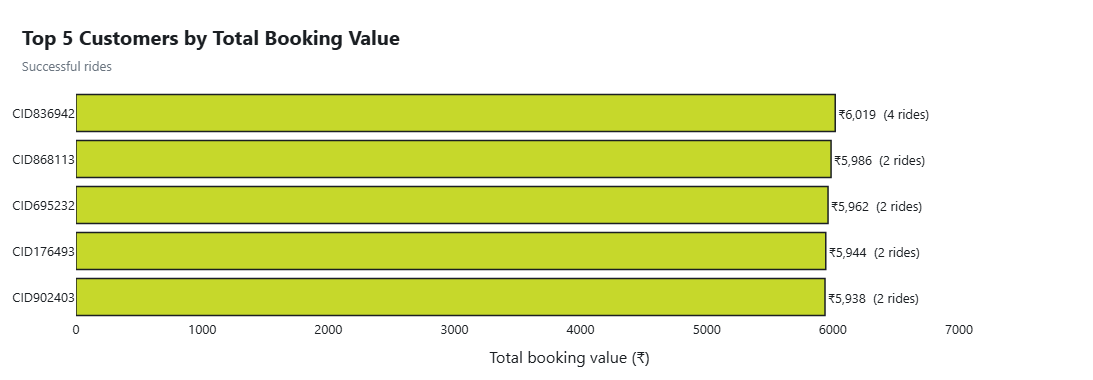

> 💡 **Insight:** No whale customers: the top-5 spend ₹5,938-6,019 each, and just **8.4%** of 94,544 customers booked more than once in July. The business is **acquisition-heavy with very low repeat usage** - a retention programme is a major opportunity.

In [16]:
cust = succ.groupby("Customer_ID").agg(Total_Value=("Booking_Value", "sum"), Rides=("Booking_ID", "count")).nlargest(5, "Total_Value").sort_values("Total_Value")
fig = go.Figure(go.Bar(x=cust["Total_Value"], y=cust.index, orientation="h", marker_color=LIME, marker_line=dict(color=INK, width=1.5),
                       text=[f"₹{v:,.0f}  ({r} ride{'s' if r > 1 else ''})" for v, r in zip(cust["Total_Value"], cust["Rides"])], textposition="outside", cliponaxis=False))
fig.update_layout(xaxis_title="Total booking value (₹)", xaxis_range=[0, cust["Total_Value"].max() * 1.3])
show(fig, "Top 5 Customers by Total Booking Value", "Successful rides", height=380)
rides_per_cust = df["Customer_ID"].value_counts()
insight(f"No whale customers: the top-5 spend ₹{cust['Total_Value'].min():,.0f}-{cust['Total_Value'].max():,.0f} each, and just **{(rides_per_cust>1).mean()*100:.1f}%** of "
        f"{len(rides_per_cust):,} customers booked more than once in July. The business is **acquisition-heavy with very low repeat usage** - a retention programme is a major opportunity.")

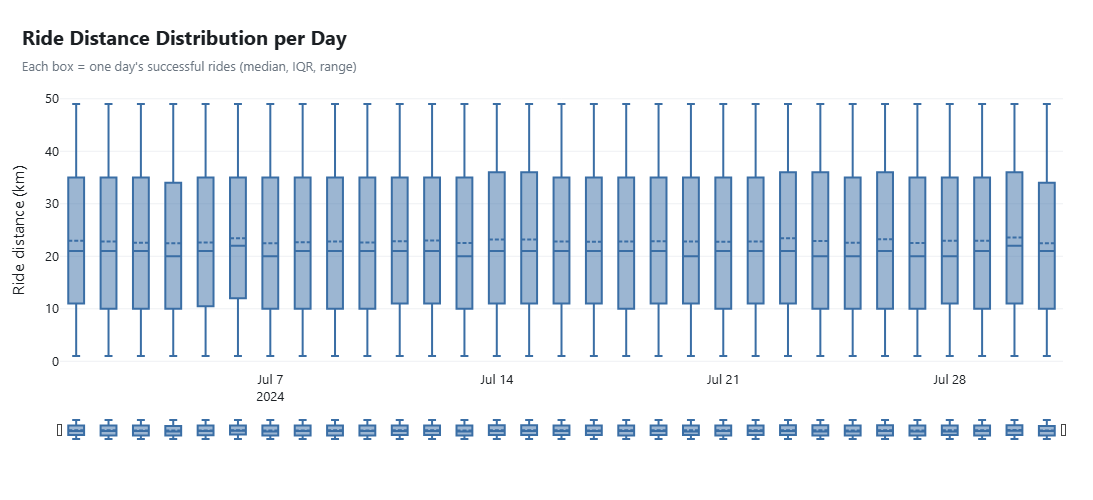

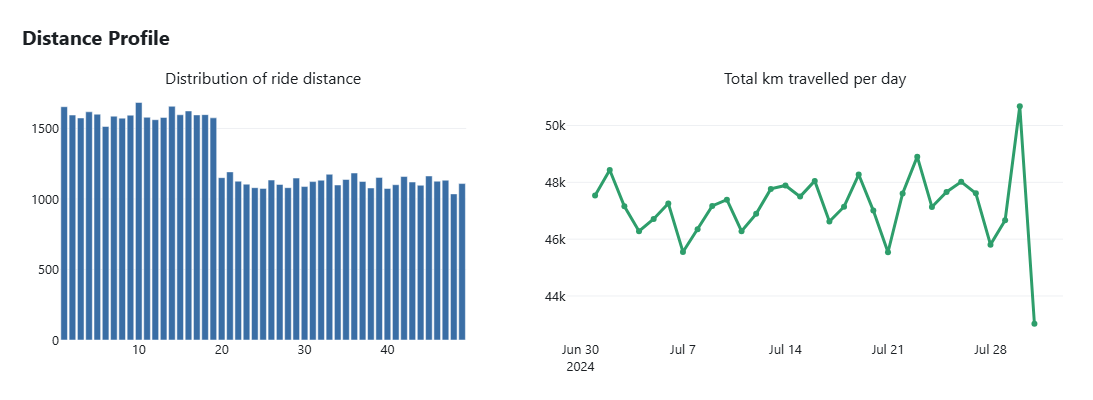

> 💡 **Insight:** Ride distance is spread **almost uniformly from 1 to 49 km** (mean 22.9 km, median 21 km), identical day to day - typical of stable city-wide demand. Daily fleet load averages 47,158 km.

In [17]:
# Ride-distance distribution per day (box = spread of individual ride distances on each date)
fig = go.Figure(box_traces(succ, "Booking_Date", "Ride_Distance", lambda k: "#3A6EA5"))
fig.update_layout(xaxis_title="", yaxis_title="Ride distance (km)", xaxis=dict(rangeslider=dict(visible=True, thickness=0.06)))
show(fig, "Ride Distance Distribution per Day", "Each box = one day's successful rides (median, IQR, range)", height=500)

fig = make_subplots(rows=1, cols=2, subplot_titles=("Distribution of ride distance", "Total km travelled per day"), column_widths=[0.45, 0.55])
hd = succ["Ride_Distance"].round().astype(int).value_counts().sort_index()
fig.add_trace(go.Bar(x=hd.index, y=hd.values, marker_color="#3A6EA5"), 1, 1)
dd = succ.groupby("Booking_Date")["Ride_Distance"].sum()
fig.add_trace(go.Scatter(x=dd.index, y=dd.values, mode="lines+markers", line=dict(color="#2E9E6B", width=3)), 1, 2)
fig.update_layout(showlegend=False)
show(fig, "Distance Profile", height=400)
insight(f"Ride distance is spread **almost uniformly from 1 to 49 km** (mean {succ['Ride_Distance'].mean():.1f} km, median {succ['Ride_Distance'].median():.0f} km), identical day to day - "
        f"typical of stable city-wide demand. Daily fleet load averages {dd.mean():,.0f} km.")

## Step 8 · Cancellation View
**Q5 Cancelled-ride reasons — customers vs drivers**, hot-spots and incomplete-ride causes.

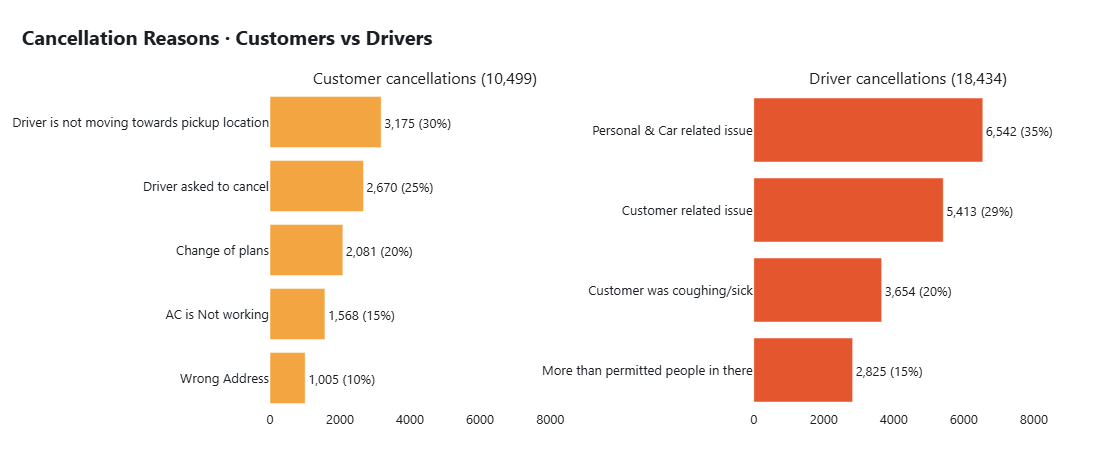

> 💡 **Insight:** Top customer reason: **Driver is not moving towards pickup location** (30%) - and *'Driver asked to cancel'* adds 25%, so **~56% of customer cancels are actually triggered by driver behaviour**. Top driver reason: **Personal & Car related issue** (35%) - vehicle readiness/driver availability, which is operationally controllable.

In [18]:
cr = df[df["Cancel_By"] == "Customer"]["Cancel_Reason"].value_counts().sort_values()
dr = df[df["Cancel_By"] == "Driver"]["Cancel_Reason"].value_counts().sort_values()
fig = make_subplots(rows=1, cols=2, subplot_titles=(f"Customer cancellations ({cr.sum():,})", f"Driver cancellations ({dr.sum():,})"), horizontal_spacing=0.22)
fig.add_trace(go.Bar(x=cr.values, y=cr.index, orientation="h", marker_color=STATUS_COLORS["Canceled by Customer"],
                     text=[f"{v:,} ({v/cr.sum()*100:.0f}%)" for v in cr.values], textposition="outside", cliponaxis=False), 1, 1)
fig.add_trace(go.Bar(x=dr.values, y=dr.index, orientation="h", marker_color=STATUS_COLORS["Canceled by Driver"],
                     text=[f"{v:,} ({v/dr.sum()*100:.0f}%)" for v in dr.values], textposition="outside", cliponaxis=False), 1, 2)
fig.update_xaxes(range=[0, max(cr.max(), dr.max()) * 1.35])
fig.update_layout(showlegend=False)
show(fig, "Cancellation Reasons · Customers vs Drivers", height=470)
insight(f"Top customer reason: **{cr.idxmax()}** ({cr.max()/cr.sum()*100:.0f}%) - and *'Driver asked to cancel'* adds {cr['Driver asked to cancel']/cr.sum()*100:.0f}%, so **~{(cr.max()+cr['Driver asked to cancel'])/cr.sum()*100:.0f}% of "
        f"customer cancels are actually triggered by driver behaviour**. Top driver reason: **{dr.idxmax()}** ({dr.max()/dr.sum()*100:.0f}%) - vehicle readiness/driver availability, "
        "which is operationally controllable.")

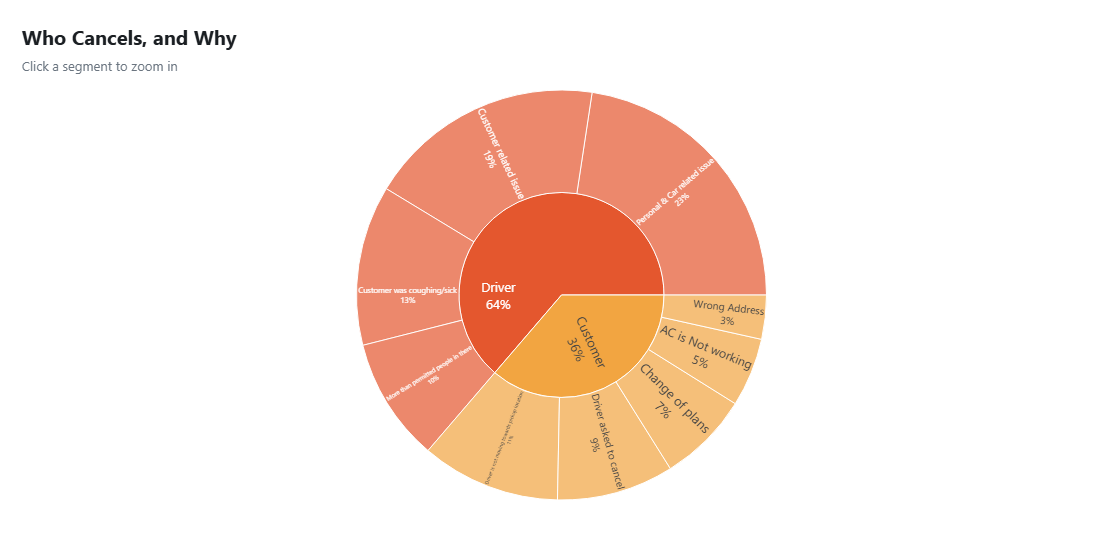

In [19]:
canc = df[~df["Is_Success"] & df["Cancel_Reason"].notna()]
fig = px.sunburst(canc, path=["Cancel_By", "Cancel_Reason"], color="Cancel_By",
                  color_discrete_map={"Customer": STATUS_COLORS["Canceled by Customer"], "Driver": STATUS_COLORS["Canceled by Driver"]})
fig.update_traces(textinfo="label+percent root", insidetextorientation="radial", hovertemplate="%{label}<br>%{value:,} rides<extra></extra>")
show(fig, "Who Cancels, and Why", "Click a segment to zoom in", height=560)

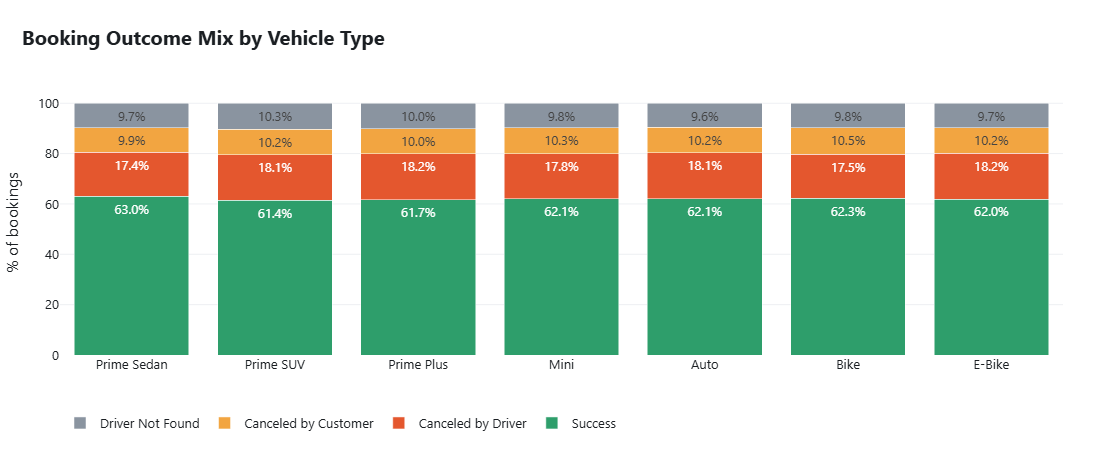

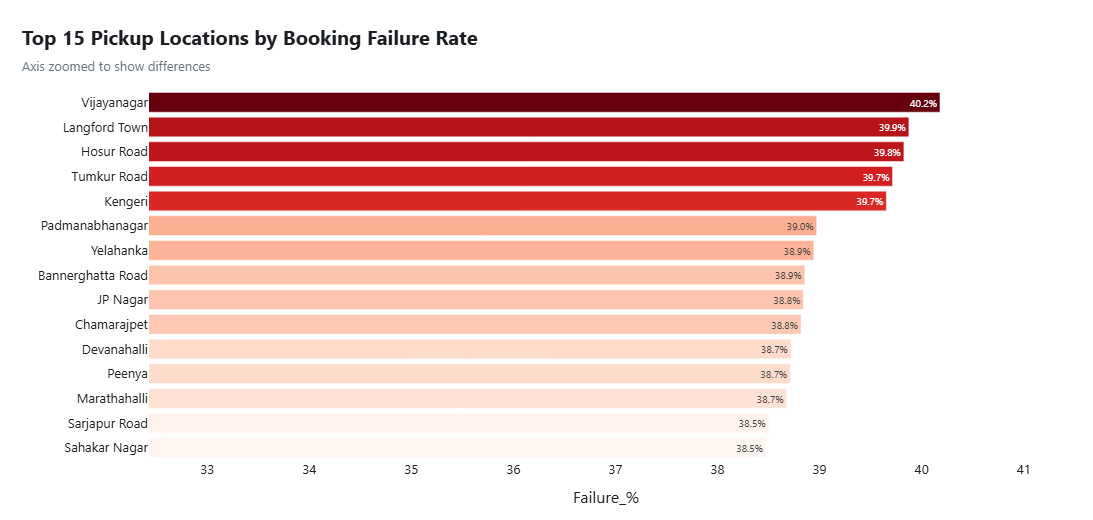

> 💡 **Insight:** Failure rate ranges only 36.0-40.2% across 50 pickup zones; worst zone **Vijayanagar** (40.2%). Differences are small, so the cancellation problem is **systemic (process/incentive-driven) rather than location-specific**.

In [20]:
# Where & when do failures concentrate?  (Failure = any non-success)
fail_rate = lambda g: (1 - g["Is_Success"].mean()) * 100
by_veh = df.groupby("Vehicle_Type").Booking_Status.value_counts(normalize=True).mul(100).unstack().reindex(VEHICLES)[STATUS_ORDER]
fig = go.Figure([go.Bar(name=s, x=by_veh.index, y=by_veh[s], marker_color=STATUS_COLORS[s], text=by_veh[s].round(1).astype(str) + "%", textposition="inside") for s in STATUS_ORDER])
fig.update_layout(barmode="stack", yaxis_title="% of bookings")
show(fig, "Booking Outcome Mix by Vehicle Type", height=450)

loc = df.groupby("Pickup_Location").apply(lambda g: pd.Series({"Bookings": len(g), "Failure_%": fail_rate(g)})).sort_values("Failure_%", ascending=False)
fig = px.bar(loc.head(15).sort_values("Failure_%"), x="Failure_%", y=loc.head(15).sort_values("Failure_%").index, orientation="h",
             color="Failure_%", color_continuous_scale="Reds", text=loc.head(15).sort_values("Failure_%")["Failure_%"].round(1).astype(str) + "%")
fig.update_layout(coloraxis_showscale=False, xaxis_range=[loc["Failure_%"].min() * 0.9, loc["Failure_%"].max() * 1.03], yaxis_title="")
show(fig, "Top 15 Pickup Locations by Booking Failure Rate", "Axis zoomed to show differences", height=520)
insight(f"Failure rate ranges only {loc['Failure_%'].min():.1f}-{loc['Failure_%'].max():.1f}% across 50 pickup zones; worst zone **{loc.index[0]}** ({loc['Failure_%'].iloc[0]:.1f}%). "
        "Differences are small, so the cancellation problem is **systemic (process/incentive-driven) rather than location-specific**.")

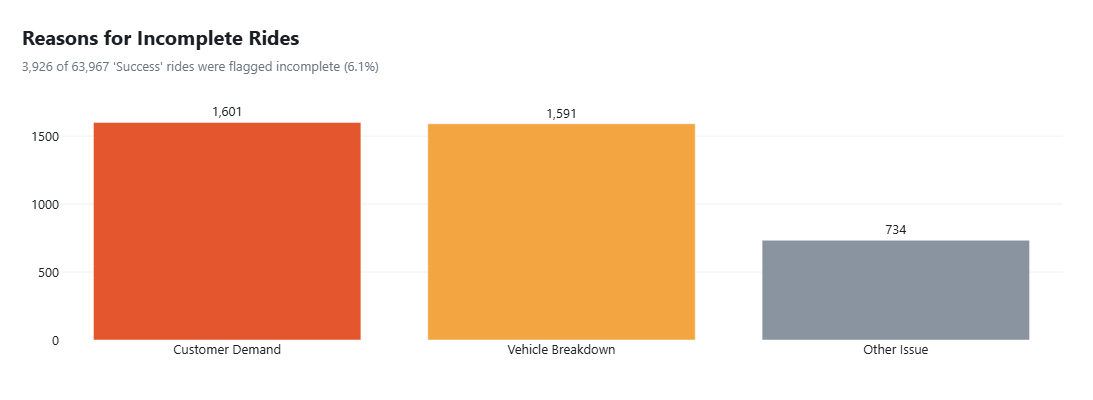

> 💡 **Insight:** Vehicle Breakdown (1,591) is nearly as common as Customer Demand (1,601) - a **preventable fleet-maintenance issue**. These rides carry ₹2.3M of booking value that may need partial-refund treatment.

In [21]:
inc = succ[succ["Is_Incomplete"]]["Incomplete_Rides_Reason"].value_counts()
fig = go.Figure(go.Bar(x=inc.index, y=inc.values, marker_color=["#E4572E", "#F2A541", "#8A94A0"], text=[f"{v:,}" for v in inc.values], textposition="outside"))
show(fig, "Reasons for Incomplete Rides", f"{succ['Is_Incomplete'].sum():,} of {len(succ):,} 'Success' rides were flagged incomplete ({succ['Is_Incomplete'].mean()*100:.1f}%)", height=400)
insight(f"Vehicle Breakdown ({inc.get('Vehicle Breakdown',0):,}) is nearly as common as Customer Demand ({inc.get('Customer Demand',0):,}) - a **preventable fleet-maintenance issue**. "
        f"These rides carry ₹{succ.loc[succ['Is_Incomplete'],'Booking_Value'].sum()/1e6:.1f}M of booking value that may need partial-refund treatment.")

## Step 9 · Ratings View
**Q4 Avg ratings by vehicle · Q9 Driver ratings distribution · Q10 Customer vs driver ratings**

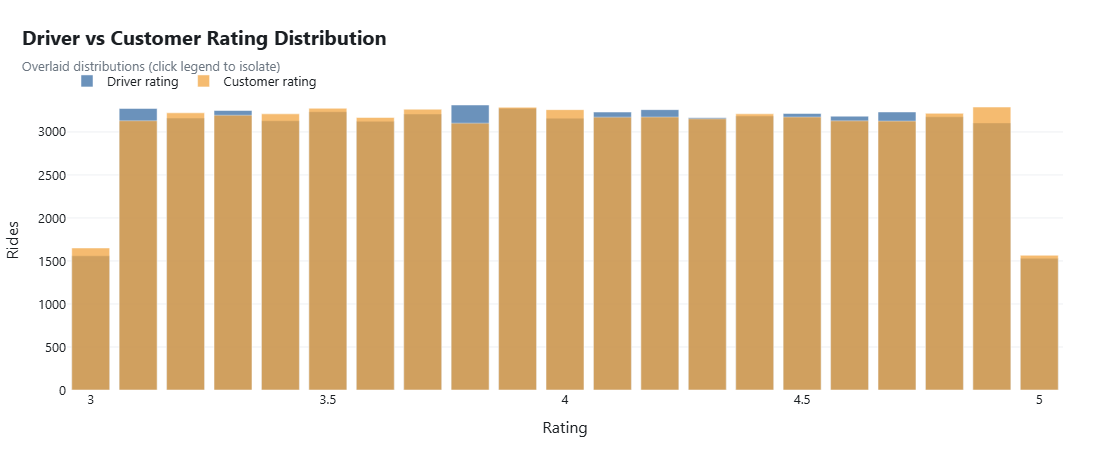

> 💡 **Insight:** Both sides average **4.00** (driver) / **4.00** (customer) with std 0.58. Ratings sit between 3.0-5.0 only - **no rating below 3 exists**, and 27% of rides get a driver rating >=4.5. A floor at 3.0 suggests rating inflation/censoring, limiting its usefulness for driver quality screening.

In [22]:
fig = go.Figure()
dvc = succ["Driver_Ratings"].round(1).value_counts().sort_index(); cvc = succ["Customer_Rating"].round(1).value_counts().sort_index()
fig.add_trace(go.Bar(x=dvc.index, y=dvc.values, name="Driver rating", marker_color="#3A6EA5", opacity=0.75))
fig.add_trace(go.Bar(x=cvc.index, y=cvc.values, name="Customer rating", marker_color="#F2A541", opacity=0.75))
fig.update_layout(barmode="overlay", xaxis_title="Rating", yaxis_title="Rides", legend=dict(orientation="h", y=1.08, x=0))
show(fig, "Driver vs Customer Rating Distribution", "Overlaid distributions (click legend to isolate)", height=450)
insight(f"Both sides average **{succ['Driver_Ratings'].mean():.2f}** (driver) / **{succ['Customer_Rating'].mean():.2f}** (customer) with std {succ['Driver_Ratings'].std():.2f}. "
        f"Ratings sit between 3.0-5.0 only - **no rating below 3 exists**, and {(succ['Driver_Ratings']>=4.5).mean()*100:.0f}% of rides get a driver rating >=4.5. "
        "A floor at 3.0 suggests rating inflation/censoring, limiting its usefulness for driver quality screening.")

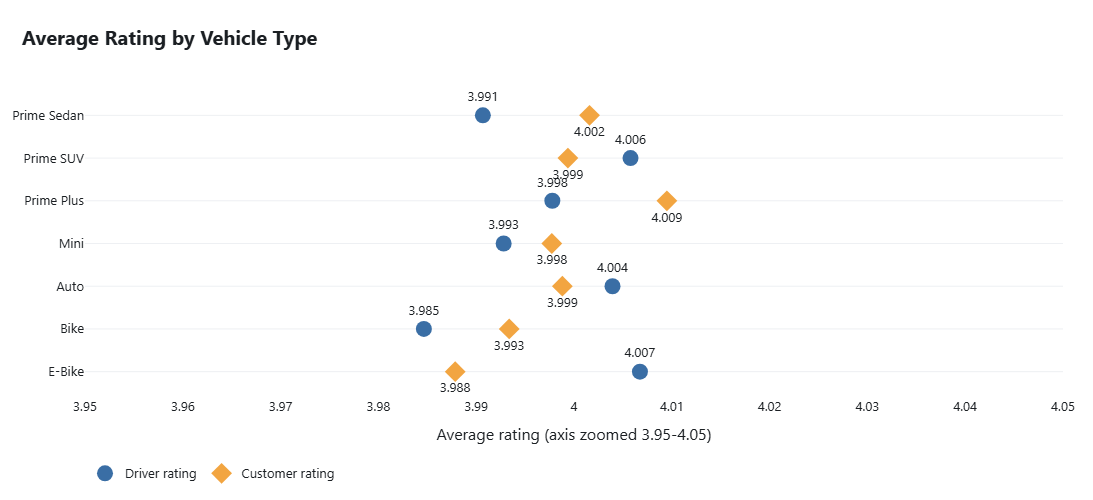

> 💡 **Insight:** Vehicle averages differ by just **0.025** rating points - service quality perception is **uniform across vehicle types**.

In [23]:
rt = succ.groupby("Vehicle_Type")[["Driver_Ratings", "Customer_Rating"]].mean().reindex(VEHICLES)
fig = go.Figure()
fig.add_trace(go.Scatter(x=rt["Driver_Ratings"], y=rt.index, mode="markers+text", name="Driver rating", marker=dict(size=16, color="#3A6EA5"),
                         text=rt["Driver_Ratings"].round(3), textposition="top center"))
fig.add_trace(go.Scatter(x=rt["Customer_Rating"], y=rt.index, mode="markers+text", name="Customer rating", marker=dict(size=16, color="#F2A541", symbol="diamond"),
                         text=rt["Customer_Rating"].round(3), textposition="bottom center"))
fig.update_layout(xaxis=dict(range=[3.95, 4.05], title="Average rating (axis zoomed 3.95-4.05)"), yaxis=dict(autorange="reversed", gridcolor="#EEF0F3"))
show(fig, "Average Rating by Vehicle Type", height=500)
insight(f"Vehicle averages differ by just **{(rt.max().max()-rt.min().min()):.3f}** rating points - service quality perception is **uniform across vehicle types**.")

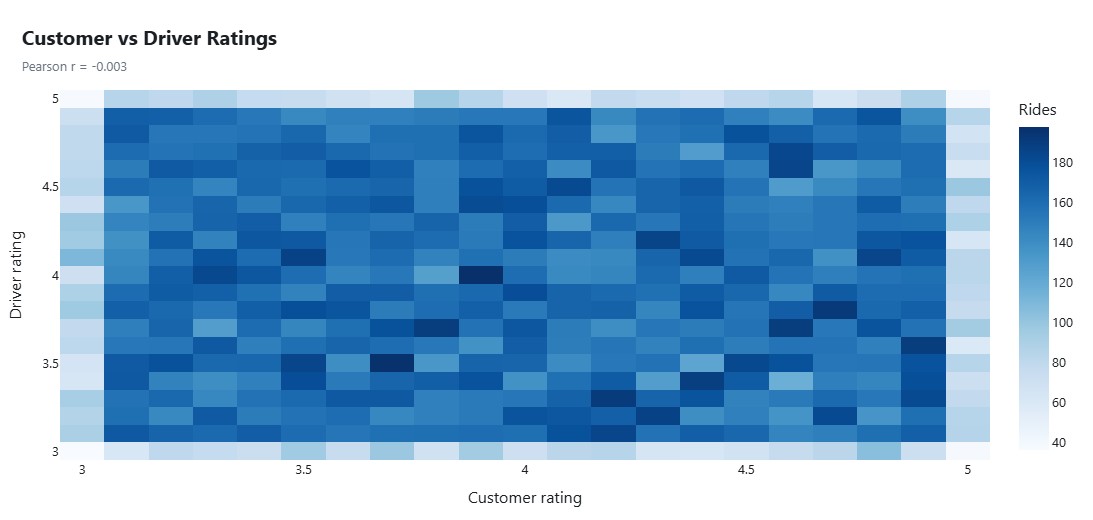

> 💡 **Insight:** Correlation is **-0.003** - essentially zero. A low rating from the customer says nothing about the rating the driver gives back: the two are **independent**, so there is no sign of tit-for-tat rating and each can be treated as a separate quality signal.

In [24]:
r = succ[["Driver_Ratings", "Customer_Rating"]].corr().iloc[0, 1]
ct = pd.crosstab(succ["Driver_Ratings"].round(1), succ["Customer_Rating"].round(1))
fig = px.imshow(ct, origin="lower", aspect="auto", color_continuous_scale="Blues", labels=dict(x="Customer rating", y="Driver rating", color="Rides"))
show(fig, "Customer vs Driver Ratings", f"Pearson r = {r:.3f}", height=520)
insight(f"Correlation is **{r:.3f}** - essentially zero. A low rating from the customer says nothing about the rating the driver gives back: the two are **independent**, "
        "so there is no sign of tit-for-tat rating and each can be treated as a separate quality signal.")

## Step 10 · Deeper EDA (from the EDA checklist)
Outliers · correlations · turnaround times · geography.

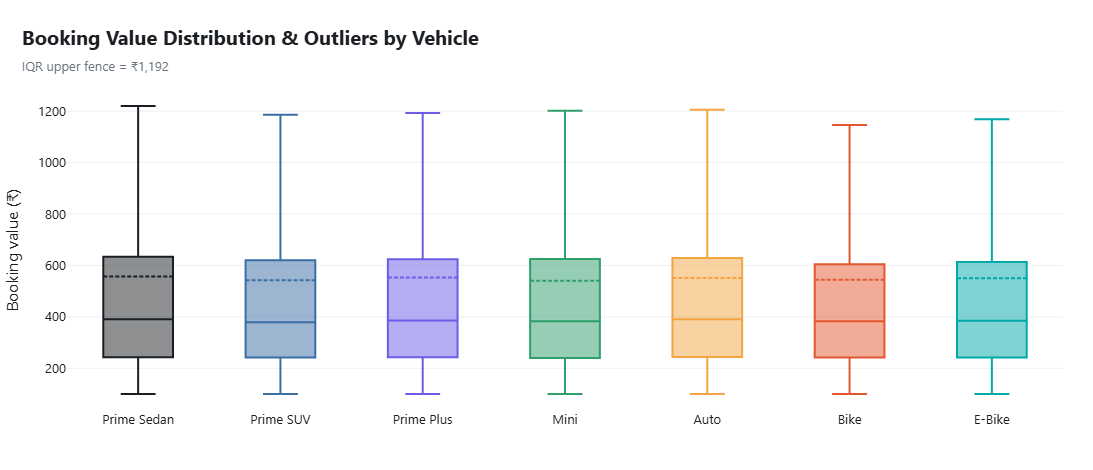

> 💡 **Insight:** Fares are **right-skewed** (median ₹385 < mean ₹548); 5,198 rides (8.1%) exceed the IQR fence (max ₹2,999). They are retained as legitimate premium trips, not errors, since distribution shape is consistent across all vehicle types.

In [25]:
# Outliers: IQR rule on booking value (right-skewed)
q1, q3 = succ["Booking_Value"].quantile([.25, .75]); iqr = q3 - q1
hi = q3 + 1.5 * iqr
n_out = (succ["Booking_Value"] > hi).sum()
fig = go.Figure(box_traces(succ, "Vehicle_Type", "Booking_Value", lambda k: VEH_COLORS[k], order=VEHICLES))
fig.update_layout(showlegend=False, xaxis_title="", yaxis_title="Booking value (₹)")
show(fig, "Booking Value Distribution & Outliers by Vehicle", f"IQR upper fence = ₹{hi:,.0f}", height=470)
insight(f"Fares are **right-skewed** (median ₹{succ['Booking_Value'].median():.0f} < mean ₹{succ['Booking_Value'].mean():.0f}); {n_out:,} rides ({n_out/len(succ)*100:.1f}%) exceed the IQR fence "
        f"(max ₹{succ['Booking_Value'].max():,.0f}). They are retained as legitimate premium trips, not errors, since distribution shape is consistent across all vehicle types.")

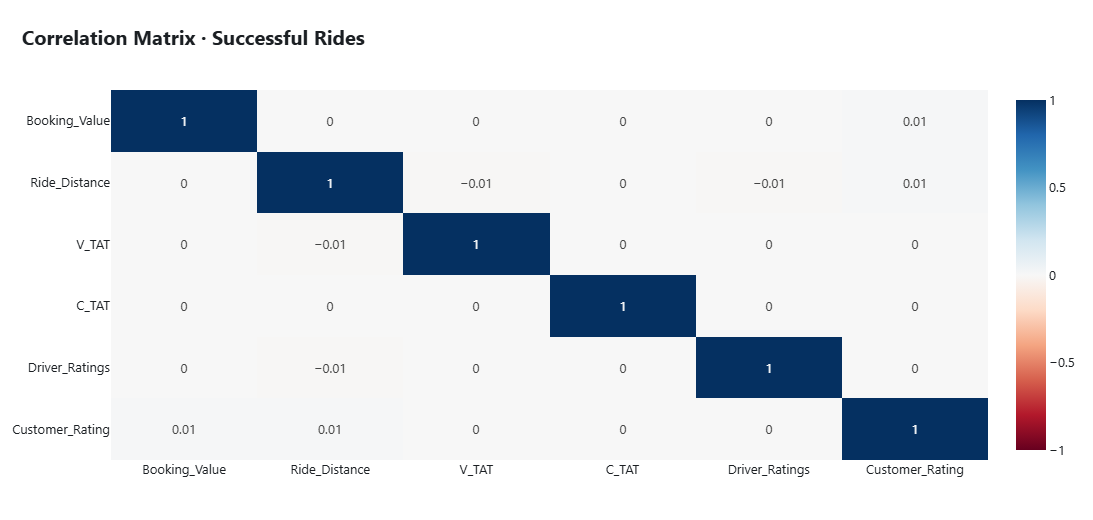

> 💡 **Insight:** Max off-diagonal |r| = **0.01**: fare is *not* driven by distance in this dataset, and ratings are unrelated to fare, distance or wait times. Pricing/rating logic cannot be reverse-engineered from these fields - a data-quality flag worth raising with the data owner (possibly anonymised/synthetic data).

In [26]:
num = ["Booking_Value", "Ride_Distance", "V_TAT", "C_TAT", "Driver_Ratings", "Customer_Rating"]
corr = succ[num].corr().round(2)
fig = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu", zmin=-1, zmax=1, aspect="auto")
show(fig, "Correlation Matrix · Successful Rides", height=520)
off = corr.where(~np.eye(len(corr), dtype=bool)).abs().max().max()
insight(f"Max off-diagonal |r| = **{off:.2f}**: fare is *not* driven by distance in this dataset, and ratings are unrelated to fare, distance or wait times. "
        "Pricing/rating logic cannot be reverse-engineered from these fields - a data-quality flag worth raising with the data owner (possibly anonymised/synthetic data).")

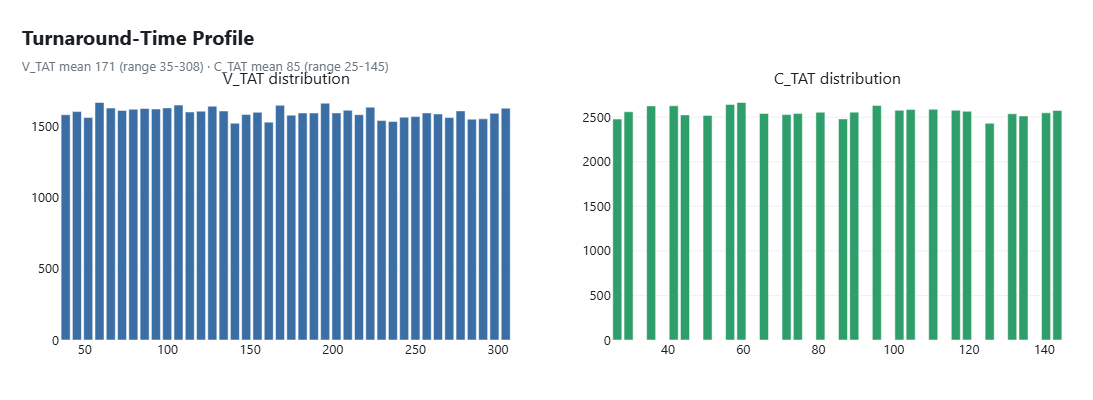

In [27]:
# Turnaround times (V_TAT = vehicle/driver arrival time, C_TAT = customer response time; units as provided)
fig = make_subplots(rows=1, cols=2, subplot_titles=("V_TAT distribution", "C_TAT distribution"))
for j, (col, colr) in enumerate([("V_TAT", "#3A6EA5"), ("C_TAT", "#2E9E6B")], 1):
    cnt, edges = np.histogram(succ[col], bins=40)
    fig.add_trace(go.Bar(x=(edges[:-1] + edges[1:]) / 2, y=cnt, marker_color=colr), 1, j)
fig.update_layout(showlegend=False)
show(fig, "Turnaround-Time Profile", f"V_TAT mean {succ['V_TAT'].mean():.0f} (range {succ['V_TAT'].min():.0f}-{succ['V_TAT'].max():.0f}) · C_TAT mean {succ['C_TAT'].mean():.0f} (range {succ['C_TAT'].min():.0f}-{succ['C_TAT'].max():.0f})", height=400)

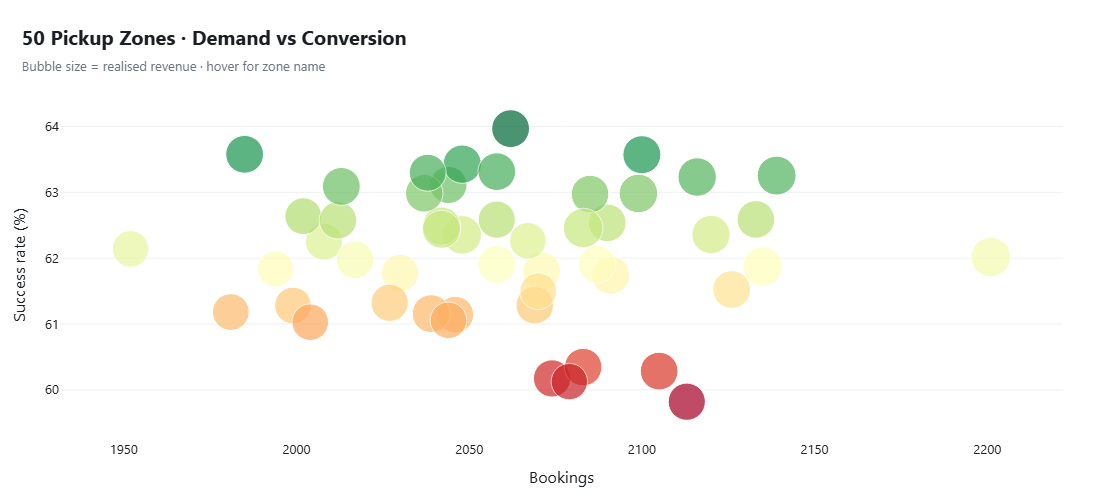

> 💡 **Insight:** Top 5 pickup zones by demand: **Banashankari** (2,201), **Yeshwanthpur** (2,139), **RT Nagar** (2,135), **Indiranagar** (2,133), **Sahakar Nagar** (2,126). 2,121 bookings (2.1%) have identical pickup and drop zone - a data-integrity item to review.

In [28]:
# Geography: demand and conversion by pickup zone
geo = df.groupby("Pickup_Location").agg(Bookings=("Booking_ID", "count"), Success_Rate=("Is_Success", "mean")).assign(Success_Rate=lambda x: x["Success_Rate"] * 100)
geo["Revenue"] = succ.groupby("Pickup_Location")["Booking_Value"].sum()
fig = px.scatter(geo.reset_index(), x="Bookings", y="Success_Rate", size="Revenue", color="Success_Rate", color_continuous_scale="RdYlGn",
                 hover_name="Pickup_Location", size_max=28, labels={"Success_Rate": "Success rate (%)"})
fig.update_layout(coloraxis_showscale=False)
show(fig, "50 Pickup Zones · Demand vs Conversion", "Bubble size = realised revenue · hover for zone name", height=500)
top_zones = geo["Bookings"].nlargest(5)
insight(f"Top 5 pickup zones by demand: {', '.join(f'**{z}** ({v:,})' for z, v in top_zones.items())}. "
        f"{(df['Same_Pickup_Drop']).sum():,} bookings ({df['Same_Pickup_Drop'].mean()*100:.1f}%) have identical pickup and drop zone - a data-integrity item to review.")

## Step 11 · SQL Analysis (10 Business Questions)
The cleaned data is loaded into a SQLite database (queries are standard SQL and run unchanged on MySQL, which is what Power BI connects to).
Each answer is **validated against pandas**.

In [29]:
sql_df = df.assign(Date=df["Booking_DT"].dt.strftime("%Y-%m-%d"), Time=df["Booking_DT"].dt.strftime("%H:%M:%S")).drop(columns=["Booking_DT", "Booking_Date"])
for c in sql_df.select_dtypes(["string", "category"]).columns: sql_df[c] = sql_df[c].astype(object)
conn = sqlite3.connect(":memory:")
sql_df.to_sql("ola_rides", conn, index=False, if_exists="replace")

def run_sql(title, query, preview=10):
    res = pd.read_sql_query(query, conn)
    display(Markdown(f"**{title}**  \n```sql\n{query.strip()}\n```"))
    if len(res) > preview: print(f"{len(res):,} rows returned - showing first {preview}")
    display(res.head(preview))
    return res

q1 = run_sql("Q1. All successful bookings", "SELECT * FROM ola_rides WHERE Booking_Status = 'Success'")
assert len(q1) == len(succ)

**Q1. All successful bookings**  
```sql
SELECT * FROM ola_rides WHERE Booking_Status = 'Success'
```

63,967 rows returned - showing first 10


,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Hour,Weekday,Is_Weekend,Day_Part,Is_Success,Is_Incomplete,Cancel_Reason,Cancel_By,Same_Pickup_Drop,Date,Time
0,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.00,30.00,None,None,No,NaN,158,Cash,13,4.10,4.00,22,Thursday,0,Late Night (22-23),1,0,None,None,0,2024-07-25,22:20:00
1,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.00,130.00,None,None,No,NaN,386,UPI,40,4.20,4.80,19,Tuesday,0,Evening (17-21),1,0,None,None,0,2024-07-30,19:59:00
2,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.00,80.00,None,None,No,NaN,822,Credit Card,45,4.00,3.00,9,Tuesday,0,Morning (6-11),1,0,None,None,0,2024-07-02,09:02:00
3,CNR8787177882,Success,CID802429,Mini,Kadugodi,Vijayanagar,231.00,90.00,None,None,No,NaN,173,UPI,41,3.40,4.60,4,Saturday,1,Night (0-5),1,0,None,None,0,2024-07-13,04:42:00
4,CNR3612067560,Success,CID476071,Bike,Tumkur Road,Whitefield,133.00,40.00,None,None,No,NaN,140,Cash,49,3.20,4.50,9,Tuesday,0,Morning (6-11),1,0,None,None,0,2024-07-23,09:51:00
5,CNR4787583516,Success,CID923404,Prime Plus,Hosur Road,Jayanagar,35.00,55.00,None,None,No,NaN,164,Cash,46,4.50,3.40,23,Monday,0,Late Night (22-23),1,0,None,None,0,2024-07-29,23:33:00
6,CNR7943634301,Success,CID647026,Prime Plus,Kammanahalli,Rajajinagar,238.00,95.00,None,None,No,NaN,399,Cash,18,3.90,4.40,4,Friday,0,Night (0-5),1,0,None,None,0,2024-07-26,04:03:00
7,CNR4524472111,Success,CID540929,Auto,Cox Town,Yelahanka,126.00,35.00,None,None,No,NaN,330,UPI,8,3.00,4.80,13,Saturday,1,Afternoon (12-16),1,0,None,None,0,2024-07-27,13:18:00
8,CNR8181602032,Success,CID167642,Bike,Indiranagar,MG Road,70.00,95.00,None,None,No,NaN,378,UPI,18,4.80,4.10,9,Tuesday,0,Morning (6-11),1,0,None,None,0,2024-07-16,09:54:00
9,CNR8090918544,Success,CID640151,Bike,Magadi Road,HSR Layout,126.00,95.00,None,None,No,NaN,343,UPI,23,3.70,3.60,10,Tuesday,0,Morning (6-11),1,0,None,None,0,2024-07-02,10:25:00


In [30]:
q2 = run_sql("Q2. Average ride distance per vehicle type (successful rides)",
    """SELECT Vehicle_Type, ROUND(AVG(Ride_Distance), 2) AS avg_distance_km
       FROM ola_rides WHERE Booking_Status = 'Success' GROUP BY Vehicle_Type ORDER BY avg_distance_km DESC""")
q3 = run_sql("Q3. Total rides cancelled by customers",
    "SELECT COUNT(*) AS cancelled_by_customer FROM ola_rides WHERE Booking_Status = 'Canceled by Customer'")
assert q3.iloc[0, 0] == (df["Booking_Status"] == "Canceled by Customer").sum()
q4 = run_sql("Q4. Top 5 customers by number of rides",
    """SELECT Customer_ID, COUNT(Booking_ID) AS total_rides FROM ola_rides
       GROUP BY Customer_ID ORDER BY total_rides DESC, Customer_ID LIMIT 5""")
q5 = run_sql("Q5. Driver cancellations due to personal & car-related issues",
    "SELECT COUNT(*) AS driver_cancel_personal_car FROM ola_rides WHERE Canceled_Rides_by_Driver = 'Personal & Car related issue'")
assert q5.iloc[0, 0] == (df["Canceled_Rides_by_Driver"] == "Personal & Car related issue").sum()

**Q2. Average ride distance per vehicle type (successful rides)**  
```sql
SELECT Vehicle_Type, ROUND(AVG(Ride_Distance), 2) AS avg_distance_km
       FROM ola_rides WHERE Booking_Status = 'Success' GROUP BY Vehicle_Type ORDER BY avg_distance_km DESC
```

,Vehicle_Type,avg_distance_km
0,E-Bike,25.15
1,Prime Plus,25.03
2,Prime Sedan,25.01
3,Mini,24.98
4,Bike,24.93
5,Prime SUV,24.88
6,Auto,10.04


**Q3. Total rides cancelled by customers**  
```sql
SELECT COUNT(*) AS cancelled_by_customer FROM ola_rides WHERE Booking_Status = 'Canceled by Customer'
```

,cancelled_by_customer
0,10499


**Q4. Top 5 customers by number of rides**  
```sql
SELECT Customer_ID, COUNT(Booking_ID) AS total_rides FROM ola_rides
       GROUP BY Customer_ID ORDER BY total_rides DESC, Customer_ID LIMIT 5
```

,Customer_ID,total_rides
0,CID954071,5
1,CID189965,4
2,CID199017,4
3,CID201733,4
4,CID263459,4


**Q5. Driver cancellations due to personal & car-related issues**  
```sql
SELECT COUNT(*) AS driver_cancel_personal_car FROM ola_rides WHERE Canceled_Rides_by_Driver = 'Personal & Car related issue'
```

,driver_cancel_personal_car
0,6542


In [31]:
q6 = run_sql("Q6. Max & min driver rating - Prime Sedan",
    """SELECT MAX(Driver_Ratings) AS max_rating, MIN(Driver_Ratings) AS min_rating
       FROM ola_rides WHERE Vehicle_Type = 'Prime Sedan' AND Driver_Ratings IS NOT NULL""")
q7 = run_sql("Q7. Rides paid via UPI", "SELECT * FROM ola_rides WHERE Payment_Method = 'UPI'")
assert len(q7) == (df["Payment_Method"] == "UPI").sum()
q8 = run_sql("Q8. Average customer rating per vehicle type",
    """SELECT Vehicle_Type, ROUND(AVG(Customer_Rating), 3) AS avg_customer_rating
       FROM ola_rides WHERE Customer_Rating IS NOT NULL GROUP BY Vehicle_Type ORDER BY avg_customer_rating DESC""")
q9 = run_sql("Q9. Total booking value of successful rides",
    "SELECT ROUND(SUM(Booking_Value), 2) AS total_successful_booking_value FROM ola_rides WHERE Booking_Status = 'Success'")
assert abs(q9.iloc[0, 0] - succ["Booking_Value"].sum()) < 1
q10 = run_sql("Q10. Incomplete rides with reason",
    "SELECT Booking_ID, Vehicle_Type, Incomplete_Rides_Reason FROM ola_rides WHERE Incomplete_Rides = 'Yes'")
assert len(q10) == df["Is_Incomplete"].sum()
print("✅ All SQL results cross-validated against pandas")

**Q6. Max & min driver rating - Prime Sedan**  
```sql
SELECT MAX(Driver_Ratings) AS max_rating, MIN(Driver_Ratings) AS min_rating
       FROM ola_rides WHERE Vehicle_Type = 'Prime Sedan' AND Driver_Ratings IS NOT NULL
```

,max_rating,min_rating
0,5.00,3.00


**Q7. Rides paid via UPI**  
```sql
SELECT * FROM ola_rides WHERE Payment_Method = 'UPI'
```

25,881 rows returned - showing first 10


,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Hour,Weekday,Is_Weekend,Day_Part,Is_Success,Is_Incomplete,Cancel_Reason,Cancel_By,Same_Pickup_Drop,Date,Time
0,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.00,130.00,None,None,No,NaN,386,UPI,40,4.20,4.80,19,Tuesday,0,Evening (17-21),1,0,None,None,0,2024-07-30,19:59:00
1,CNR8787177882,Success,CID802429,Mini,Kadugodi,Vijayanagar,231.00,90.00,None,None,No,NaN,173,UPI,41,3.40,4.60,4,Saturday,1,Night (0-5),1,0,None,None,0,2024-07-13,04:42:00
2,CNR4524472111,Success,CID540929,Auto,Cox Town,Yelahanka,126.00,35.00,None,None,No,NaN,330,UPI,8,3.00,4.80,13,Saturday,1,Afternoon (12-16),1,0,None,None,0,2024-07-27,13:18:00
3,CNR8181602032,Success,CID167642,Bike,Indiranagar,MG Road,70.00,95.00,None,None,No,NaN,378,UPI,18,4.80,4.10,9,Tuesday,0,Morning (6-11),1,0,None,None,0,2024-07-16,09:54:00
4,CNR8090918544,Success,CID640151,Bike,Magadi Road,HSR Layout,126.00,95.00,None,None,No,NaN,343,UPI,23,3.70,3.60,10,Tuesday,0,Morning (6-11),1,0,None,None,0,2024-07-02,10:25:00
5,CNR9975925287,Success,CID162055,Prime SUV,Magadi Road,RT Nagar,42.00,30.00,None,None,No,NaN,343,UPI,17,3.00,3.80,11,Tuesday,0,Morning (6-11),1,0,None,None,0,2024-07-09,11:11:00
6,CNR4443921904,Success,CID654618,Mini,Tumkur Road,Koramangala,231.00,50.00,None,None,No,NaN,286,UPI,44,4.00,3.30,21,Friday,0,Evening (17-21),1,0,None,None,0,2024-07-19,21:18:00
7,CNR7194303296,Success,CID538245,Mini,Mysore Road,Hennur,175.00,50.00,None,None,No,NaN,141,UPI,35,4.70,3.10,3,Thursday,0,Night (0-5),1,0,None,None,0,2024-07-25,03:44:00
8,CNR6494005067,Success,CID805360,Auto,Yelahanka,Malleshwaram,84.00,60.00,None,None,No,NaN,214,UPI,2,3.30,4.50,17,Monday,0,Evening (17-21),1,0,None,None,0,2024-07-15,17:11:00
9,CNR7142279862,Success,CID378034,E-Bike,Yeshwanthpur,JP Nagar,210.00,45.00,None,None,No,NaN,461,UPI,49,4.50,3.10,5,Sunday,1,Night (0-5),1,0,None,None,0,2024-07-14,05:25:00


**Q8. Average customer rating per vehicle type**  
```sql
SELECT Vehicle_Type, ROUND(AVG(Customer_Rating), 3) AS avg_customer_rating
       FROM ola_rides WHERE Customer_Rating IS NOT NULL GROUP BY Vehicle_Type ORDER BY avg_customer_rating DESC
```

... (3 outputs left out)

**Q10. Incomplete rides with reason**  
```sql
SELECT Booking_ID, Vehicle_Type, Incomplete_Rides_Reason FROM ola_rides WHERE Incomplete_Rides = 'Yes'
```

3,926 rows returned - showing first 10


,Booking_ID,Vehicle_Type,Incomplete_Rides_Reason
0,CNR5176704322,Prime Plus,Customer Demand
1,CNR9312632867,Prime SUV,Vehicle Breakdown
2,CNR7924302885,Auto,Customer Demand
3,CNR1640228587,Prime Sedan,Other Issue
4,CNR7623690602,Bike,Other Issue
5,CNR9590311980,Auto,Customer Demand
6,CNR5863244684,E-Bike,Customer Demand
7,CNR9526078867,E-Bike,Customer Demand
8,CNR7154043084,Auto,Customer Demand
9,CNR3193710797,Prime Sedan,Other Issue


✅ All SQL results cross-validated against pandas


## Step 12 · Insights & Recommendations (auto-computed)

In [32]:
wk_avg = (df.groupby("Weekday", observed=True).size() / days_per_weekday)
rec = f"""
### 📌 Key findings
1. **Conversion is the core problem** - only **{K['success_rate']:.1f}%** of {K['bookings']:,} bookings complete; **₹{K['lost']/1e6:.1f}M** ({K['lost']/(K['lost']+K['revenue'])*100:.0f}% of demand value) is lost.
2. **Drivers, not customers, cause most failures** - driver cancellations ({K['driver_cancel']:.1f}%) are ~{K['driver_cancel']/K['cust_cancel']:.1f}x customer cancellations ({K['cust_cancel']:.1f}%), and "driver asked to cancel" / "driver not moving" explain most customer-initiated cancels.
3. **Demand is flat** by hour ({hr.min():.0f}-{hr.max():.0f}/hr) and weekday - there is no rush-hour peak to staff around.
4. **Auto is structurally different** - {a['Avg_Distance_km']:.1f} km avg ride vs ~{o['Avg_Distance_km'].mean():.0f} km elsewhere at the same fare level (₹{a['Revenue_per_Km']:.0f}/km vs ₹{o['Revenue_per_Km'].mean():.0f}/km).
5. **Cash + UPI = {pay.loc[['Cash','UPI'],'Share_%'].sum():.0f}% of revenue**; cards are only {pay.loc[['Credit Card','Debit Card'],'Share_%'].sum():.0f}%.
6. **Retention is weak** - only {(rides_per_cust>1).mean()*100:.1f}% of customers booked more than once.
7. **Ratings carry little signal** - floor of 3.0, mean ~{succ['Driver_Ratings'].mean():.1f}, uncorrelated with fare/distance/TAT or each other (r = {r:.3f}).

### 🎯 Recommendations
| Priority | Action | Why (evidence) |
|---|---|---|
| 🔴 High | Driver-cancellation penalties + completion bonuses; pre-trip vehicle readiness check | Biggest leakage pool (₹{by_status['Canceled by Driver']/1e6:.1f}M); top reason is personal/car issues |
| 🔴 High | Auto-reassign on driver cancel instead of letting the booking fail | Recovers a share of ₹{(by_status['Canceled by Driver']+by_status['Driver Not Found'])/1e6:.1f}M driver-side loss |
| 🟠 Medium | Review Auto short-hop pricing (distance-slab / fare benchmarking) | Auto earns ~2.5x the ₹/km of other vehicles on short hops - likely a pricing/competitiveness gap |
| 🟠 Medium | UPI cashback to shift cash users | Cash is {pay.loc['Cash','Share_%']:.0f}% of revenue |
| 🟡 Medium | Loyalty / second-ride coupons | {(1-(rides_per_cust>1).mean())*100:.0f}% of customers never rebook |
| 🟡 Low | Preventive maintenance programme | Vehicle breakdown = {inc.get('Vehicle Breakdown',0):,} incomplete rides |
| 🟢 Data | Widen rating scale / audit pricing logic & duplicate pickup=drop rows | Ratings floor at 3.0; fare uncorrelated with distance |

> **Limitations:** single month (no seasonality/YoY), `Booking_Value` for cancelled rides is the *quoted* value (not revenue), and currency is assumed INR.
"""
display(Markdown(rec))


### 📌 Key findings
1. **Conversion is the core problem** - only **62.1%** of 103,024 bookings complete; **₹21.5M** (38% of demand value) is lost.
2. **Drivers, not customers, cause most failures** - driver cancellations (17.9%) are ~1.8x customer cancellations (10.2%), and "driver asked to cancel" / "driver not moving" explain most customer-initiated cancels.
3. **Demand is flat** by hour (135-142/hr) and weekday - there is no rush-hour peak to staff around.
4. **Auto is structurally different** - 10.0 km avg ride vs ~25 km elsewhere at the same fare level (₹55/km vs ₹22/km).
5. **Cash + UPI = 95% of revenue**; cards are only 5%.
6. **Retention is weak** - only 8.4% of customers booked more than once.
7. **Ratings carry little signal** - floor of 3.0, mean ~4.0, uncorrelated with fare/distance/TAT or each other (r = -0.003).

### 🎯 Recommendations
| Priority | Action | Why (evidence) |
|---|---|---|
| 🔴 High | Driver-cancellation penalties + completion bonuses; pre-trip vehicle readiness check | Biggest leakage pool (₹10.2M); top reason is personal/car issues |
| 🔴 High | Auto-reassign on driver cancel instead of letting the booking fail | Recovers a share of ₹15.7M driver-side loss |
| 🟠 Medium | Review Auto short-hop pricing (distance-slab / fare benchmarking) | Auto earns ~2.5x the ₹/km of other vehicles on short hops - likely a pricing/competitiveness gap |
| 🟠 Medium | UPI cashback to shift cash users | Cash is 55% of revenue |
| 🟡 Medium | Loyalty / second-ride coupons | 92% of customers never rebook |
| 🟡 Low | Preventive maintenance programme | Vehicle breakdown = 1,591 incomplete rides |
| 🟢 Data | Widen rating scale / audit pricing logic & duplicate pickup=drop rows | Ratings floor at 3.0; fare uncorrelated with distance |

> **Limitations:** single month (no seasonality/YoY), `Booking_Value` for cancelled rides is the *quoted* value (not revenue), and currency is assumed INR.


## Step 13 · Export Artefacts for Power BI / Streamlit

In [33]:
out = Path("outputs"); out.mkdir(exist_ok=True)
df.drop(columns=["Booking_Date"]).to_csv(out / "ola_rides_clean.csv", index=False)
veh.round(2).to_csv(out / "vehicle_summary.csv")
pay.round(2).to_csv(out / "payment_summary.csv")
with sqlite3.connect(out / "ola_rides.db") as c:
    sql_df.to_sql("ola_rides", c, index=False, if_exists="replace")
for f in sorted(out.iterdir()): print(f"{f.name:<24}{f.stat().st_size/1e6:>8.1f} MB")

ola_rides.db                18.2 MB
ola_rides_clean.csv         18.9 MB
payment_summary.csv          0.0 MB
vehicle_summary.csv          0.0 MB


---
### ✅ Project Summary
Built a reproducible pipeline - **data audit → cleaning/validation → 25+ interactive visuals → SQL (10 queries, cross-validated) → business recommendations** - on 103K ride bookings.
Next steps: load `ola_rides_clean.csv` / MySQL into **Power BI** (Overall · Vehicle Type · Revenue · Cancellation · Ratings pages) and deploy a **Streamlit** app on top of `ola_rides.db`.

In [34]:
import mysql.connector

try:
    connection = mysql.connector.connect(
        host="localhost",
        user="root",
        password="@Suman2002"
    )

    if connection.is_connected():
        print("Successfully connected to MySQL!")
        print("MySQL Version:", connection.get_server_info())

except mysql.connector.Error as error:
    print("MySQL Connection Error:", error)

finally:
    if 'connection' in locals() and connection.is_connected():
        connection.close()
        print("Connection closed.")

Successfully connected to MySQL!
MySQL Version: 8.0.46
Connection closed.
